# Junyi cycle-corrected ablation + independent confirmation

Notebook này thực hiện **external validation trên log học toán thực tế của Junyi Academy**. Nó giữ frozen exploratory run để truy vết, sau đó thực hiện SCC correction, component ablation và một independent confirmation holdout. Nó bổ sung cho simulator hiện tại, không thay thế simulator.

## Phạm vi claim

- Junyi dùng để kiểm tra next-response prediction và calibration trên dữ liệu người học thật.
- Notebook **không** suy ra causal learning gain hoặc closed-loop policy benefit từ logged data.
- Quan hệ graph lấy từ trường prerequisite chính thức trong `junyi_Exercise_table.csv`.
- Mọi dự đoán được tạo trước khi quan sát response hiện tại.

## Protocol được đóng băng

1. Sample và chia theo **user**, không chia theo interaction.
2. Train users chỉ dùng để ước lượng exercise difficulty.
3. Development users dùng để chọn BKT parameters, shared decay và graph weight.
4. Test users không được dùng trong preprocessing thống kê hoặc tuning.
5. So sánh AdaptiveLMS/Elo, BKT, GAM-KT và Graph-GAM-KT trên cùng chronological test streams.
6. Báo cáo Log Loss, Brier, ECE, AUC, paired bootstrap CI, rank-biserial effect và Holm correction.

Dataset source and terms: https://edudata.readthedocs.io/en/doc/build/blitz/junyi/junyi.html

Required dataset citation: H.-S. Chang, H.-J. Hsu, and K.-T. Chen, “Modeling Exercise Relationships in E-Learning: A Unified Approach,” EDM 2015.


In [3]:
from __future__ import annotations

import hashlib
import json
import math
import os
import re
import shutil
import subprocess
import sys
import tarfile
import time
import warnings
import zipfile
from dataclasses import dataclass, field
from functools import lru_cache
from itertools import product
from pathlib import Path

import numpy as np
import pandas as pd

try:
    import requests
    import networkx as nx
    import matplotlib.pyplot as plt
    import seaborn as sns
    from scipy.stats import rankdata, wilcoxon
    from sklearn.metrics import accuracy_score, brier_score_loss, log_loss, roc_auc_score
except ImportError:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "requests", "networkx", "matplotlib", "seaborn", "scipy", "scikit-learn",
    ])
    import requests
    import networkx as nx
    import matplotlib.pyplot as plt
    import seaborn as sns
    from scipy.stats import rankdata, wilcoxon
    from sklearn.metrics import accuracy_score, brier_score_loss, log_loss, roc_auc_score

warnings.filterwarnings("ignore", category=RuntimeWarning)
sns.set_theme(style="whitegrid", context="notebook")

IN_COLAB = Path("/content").exists()
SMOKE_TEST = os.environ.get("JUNYI_SMOKE_TEST", "0") == "1"
GLOBAL_SEED = 20260722
np.random.seed(GLOBAL_SEED)

print({"in_colab": IN_COLAB, "smoke_test": SMOKE_TEST, "seed": GLOBAL_SEED})


{'in_colab': True, 'smoke_test': False, 'seed': 20260722}


## 1. Configuration and license gate

Junyi chỉ cho phép sử dụng phi thương mại và yêu cầu trích dẫn dataset paper. Notebook không tự chấp nhận điều khoản thay người chạy. Nếu muốn notebook tự tải, hãy đổi `ACCEPT_JUNYI_NONCOMMERCIAL_TERMS=True` và `AUTO_DOWNLOAD=True`.

Downloader trong notebook dùng HTTPS và resume vì CLI `EduData 0.0.18` có timeout 15 giây. Archive Junyi là **RAR5** khoảng **1.30 GB**, nên notebook dùng bản `unrar` hiện đại có kiểm tra SHA-256 thay cho `p7zip 16.02` cũ của Colab. Dữ liệu sau giải nén cần thêm vài GB trên ổ runtime. Chạy lại cùng cell sẽ tiếp tục từ file `.part` nếu kết nối bị ngắt.

Trên Colab, dataset được lưu ở ổ runtime tạm `/content/junyi_data`, **không nằm trên Google Drive**. Chỉ kết quả cuối cùng được copy sang Drive. Vì vậy phiên làm việc mới sẽ phải tải dataset lại; archive được xóa sau khi hai CSV cần thiết đã được xác minh.

Nếu tải thủ công trong cùng phiên Colab, đặt hai file sau dưới `/content/junyi_data`:

- `junyi_ProblemLog_original.csv`
- `junyi_Exercise_table.csv`


In [4]:
ACCEPT_JUNYI_NONCOMMERCIAL_TERMS = True
AUTO_DOWNLOAD = True
KEEP_JUNYI_ARCHIVE = False
RUN_UNTOUCHED_TEST = True

QUICK_MODE = False
CHUNK_SIZE = 500_000
MIN_EVENTS_PER_USER = 20
MAX_EVENTS_PER_USER = 300
EVAL_WARMUP_EVENTS = 5

TRAIN_USER_CAP = 4_000
DEV_USER_CAP = 1_000
TEST_USER_CAP = 1_000
DEV_TUNE_USER_CAP = 300
BOOTSTRAP_SAMPLES = 2_000
FEATURE_DIM = 64

if QUICK_MODE:
    TRAIN_USER_CAP, DEV_USER_CAP, TEST_USER_CAP = 800, 250, 250
    DEV_TUNE_USER_CAP = 100
    MAX_EVENTS_PER_USER = 150
    BOOTSTRAP_SAMPLES = 500

if SMOKE_TEST:
    CHUNK_SIZE = 500
    TRAIN_USER_CAP, DEV_USER_CAP, TEST_USER_CAP = 40, 15, 15
    DEV_TUNE_USER_CAP = 8
    MIN_EVENTS_PER_USER = 12
    MAX_EVENTS_PER_USER = 30
    EVAL_WARMUP_EVENTS = 3
    BOOTSTRAP_SAMPLES = 200

if not SMOKE_TEST and not ACCEPT_JUNYI_NONCOMMERCIAL_TERMS:
    raise ValueError(
        "Read the Junyi terms, then set ACCEPT_JUNYI_NONCOMMERCIAL_TERMS=True "
        "to confirm non-commercial research use."
    )

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    DATA_DIR = Path("/content/junyi_data")
    DRIVE_RESULT_DIR = Path("/content/drive/MyDrive/Graduation-Thesis-Research/Junyi-External-Validation")
else:
    DATA_DIR = Path("./junyi_data")
    DRIVE_RESULT_DIR = None

OUTPUT_DIR = Path("/content/junyi_external_validation_outputs") if IN_COLAB else Path("./junyi_external_validation_outputs")
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print({
    "data_dir": str(DATA_DIR), "output_dir": str(OUTPUT_DIR),
    "user_caps": {"train": TRAIN_USER_CAP, "dev": DEV_USER_CAP, "test": TEST_USER_CAP},
    "max_events_per_user": MAX_EVENTS_PER_USER,
})


Mounted at /content/drive
{'data_dir': '/content/junyi_data', 'output_dir': '/content/junyi_external_validation_outputs', 'user_caps': {'train': 4000, 'dev': 1000, 'test': 1000}, 'max_events_per_user': 300}


In [5]:
def make_smoke_dataset(root: Path):
    root.mkdir(parents=True, exist_ok=True)
    rng = np.random.default_rng(GLOBAL_SEED)
    exercises = [f"exercise_{i}" for i in range(10)]
    exercise_rows = []
    for i, exercise in enumerate(exercises):
        parent = "" if i == 0 else exercises[(i - 1) // 2]
        exercise_rows.append({
            "name": exercise,
            "prerequisites": parent,
            "topic": f"topic_{i // 3}",
            "area": "arithmetic" if i < 5 else "algebra",
            "seconds_per_fast_problem": 10 + i,
        })
    pd.DataFrame(exercise_rows).to_csv(root / "junyi_Exercise_table.csv", index=False)

    rows = []
    base_time = pd.Timestamp("2015-01-01", tz="UTC")
    for user_index in range(90):
        ability = rng.normal(0.0, 0.65)
        mastery = np.zeros(len(exercises), dtype=float)
        for step in range(24 + user_index % 7):
            ex_index = (step + user_index) % len(exercises)
            prerequisite_bonus = 0.0 if ex_index == 0 else 0.30 * mastery[(ex_index - 1) // 2]
            p = 1 / (1 + np.exp(-(ability + mastery[ex_index] + prerequisite_bonus - 0.12 * ex_index)))
            y = int(rng.random() < p)
            mastery[ex_index] += 0.12 * (1 - mastery[ex_index])
            timestamp = base_time + pd.Timedelta(minutes=7 * step + user_index * 100)
            rows.append({
                "user_id": f"smoke_user_{user_index}",
                "exercise": exercises[ex_index],
                "problem_type": f"template_{ex_index % 3}",
                "time_done": int(timestamp.timestamp() * 1_000_000),
                "correct": bool(y),
            })
    pd.DataFrame(rows).to_csv(root / "junyi_ProblemLog_original.csv", index=False)


if SMOKE_TEST:
    make_smoke_dataset(DATA_DIR)

JUNYI_ARCHIVE_URL = (
    "https://base.ustc.edu.cn/data/"
    "JunyiAcademy_Math_Practicing_Log/junyi.rar"
)
RARLAB_VERSION = "723"
RARLAB_PACKAGE_URL = f"https://www.rarlab.com/rar/rarlinux-x64-{RARLAB_VERSION}.tar.gz"
RARLAB_PACKAGE_SHA256 = "759b4b6aa0d9f77131882162951193f3a0e54bf60e1d8dc4255aa308accab588"


def find_junyi_files(root: Path):
    problem_logs = sorted(root.rglob("*ProblemLog_original*.csv"))
    exercise_tables = sorted(root.rglob("*Exercise_table*.csv"))
    return (
        problem_logs[0] if problem_logs else None,
        exercise_tables[0] if exercise_tables else None,
    )


def remote_file_size(url: str) -> int | None:
    response = requests.head(url, allow_redirects=True, timeout=(30, 120))
    response.raise_for_status()
    value = response.headers.get("content-length")
    return int(value) if value else None


def download_with_resume(url: str, destination: Path, report_every_seconds: float = 5.0):
    destination.parent.mkdir(parents=True, exist_ok=True)
    partial = destination.with_suffix(destination.suffix + ".part")
    expected_size = remote_file_size(url)

    if destination.exists():
        current_size = destination.stat().st_size
        if expected_size is None or current_size == expected_size:
            print(f"Archive already complete: {destination} ({current_size / 1024**3:.3f} GiB)")
            return destination
        if current_size < expected_size and not partial.exists():
            destination.replace(partial)
            print(f"Recovered an incomplete EduData download as {partial.name}.")
        elif current_size != expected_size:
            raise RuntimeError(
                f"Unexpected archive size at {destination}: {current_size:,} bytes; "
                f"expected {expected_size:,}. Move that file aside, then rerun this cell."
            )

    downloaded = partial.stat().st_size if partial.exists() else 0
    headers = {"Range": f"bytes={downloaded}-"} if downloaded else {}
    print({
        "download_url": url,
        "resume_from_gib": round(downloaded / 1024**3, 3),
        "expected_gib": round(expected_size / 1024**3, 3) if expected_size else None,
        "partial_file": str(partial),
    })

    try:
        with requests.get(
            url,
            headers=headers,
            stream=True,
            allow_redirects=True,
            timeout=(30, 180),
        ) as response:
            response.raise_for_status()
            resumed = downloaded > 0 and response.status_code == 206
            if downloaded > 0 and not resumed:
                print("Server ignored Range; restarting the archive download safely.")
                downloaded = 0
            mode = "ab" if resumed else "wb"
            total = expected_size
            last_report = time.monotonic()
            with open(partial, mode) as stream:
                for chunk in response.iter_content(chunk_size=8 * 1024 * 1024):
                    if not chunk:
                        continue
                    stream.write(chunk)
                    downloaded += len(chunk)
                    now = time.monotonic()
                    if now - last_report >= report_every_seconds:
                        if total:
                            print(
                                f"Downloaded {downloaded / 1024**3:.3f}/{total / 1024**3:.3f} GiB "
                                f"({100 * downloaded / total:.1f}%)"
                            )
                        else:
                            print(f"Downloaded {downloaded / 1024**3:.3f} GiB")
                        last_report = now
                stream.flush()
                os.fsync(stream.fileno())
    except requests.RequestException as error:
        saved = partial.stat().st_size if partial.exists() else 0
        raise RuntimeError(
            f"Junyi download interrupted after {saved / 1024**3:.3f} GiB. "
            "Rerun this same cell to resume from the .part file. "
            f"Original network error: {type(error).__name__}: {error}"
        ) from error

    if expected_size is not None and downloaded != expected_size:
        raise RuntimeError(
            f"Incomplete Junyi archive: downloaded {downloaded:,} of {expected_size:,} bytes. "
            "Rerun this cell to resume."
        )
    partial.replace(destination)
    print(f"Download complete: {destination} ({downloaded / 1024**3:.3f} GiB)")
    return destination


def sha256_path(path: Path, block_size: int = 8 * 1024 * 1024) -> str:
    digest = hashlib.sha256()
    with open(path, "rb") as stream:
        while True:
            block = stream.read(block_size)
            if not block:
                break
            digest.update(block)
    return digest.hexdigest()


def ensure_modern_unrar() -> Path:
    system_unrar = shutil.which("unrar")
    if system_unrar:
        probe = subprocess.run(
            [system_unrar], text=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT
        )
        match = re.search(r"UNRAR\s+(\d+)\.(\d+)", probe.stdout, flags=re.IGNORECASE)
        if match and int(match.group(1)) >= 5:
            print(f"Using system RAR5 extractor: {match.group(0)}")
            return Path(system_unrar)

    tool_dir = Path("/content/junyi_rar_tools") if IN_COLAB else Path("/tmp/junyi_rar_tools")
    tool_dir.mkdir(parents=True, exist_ok=True)
    package_path = tool_dir / f"rarlinux-x64-{RARLAB_VERSION}.tar.gz"
    unrar_path = tool_dir / "unrar"

    if unrar_path.exists():
        probe = subprocess.run(
            [str(unrar_path)], text=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT
        )
        if "UNRAR 7.23" in probe.stdout:
            return unrar_path

    if package_path.exists() and sha256_path(package_path) != RARLAB_PACKAGE_SHA256:
        package_path.unlink()

    if not package_path.exists():
        print("Downloading the pinned official RARLAB extractor (about 730 KiB)...")
        partial = package_path.with_suffix(package_path.suffix + ".part")
        digest = hashlib.sha256()
        with requests.get(
            RARLAB_PACKAGE_URL, stream=True, allow_redirects=True, timeout=(30, 120)
        ) as response:
            response.raise_for_status()
            with open(partial, "wb") as stream:
                for chunk in response.iter_content(chunk_size=1024 * 1024):
                    if chunk:
                        stream.write(chunk)
                        digest.update(chunk)
        if digest.hexdigest() != RARLAB_PACKAGE_SHA256:
            partial.unlink(missing_ok=True)
            raise RuntimeError("RARLAB package SHA-256 mismatch; refusing to execute it.")
        partial.replace(package_path)

    if sha256_path(package_path) != RARLAB_PACKAGE_SHA256:
        raise RuntimeError("Cached RARLAB package SHA-256 mismatch; refusing to execute it.")

    with tarfile.open(package_path, mode="r:gz") as bundle:
        member = bundle.getmember("rar/unrar")
        source = bundle.extractfile(member)
        if source is None:
            raise RuntimeError("Official RARLAB package does not contain rar/unrar.")
        temporary_unrar = unrar_path.with_suffix(".tmp")
        with source, open(temporary_unrar, "wb") as destination:
            shutil.copyfileobj(source, destination)
        temporary_unrar.chmod(0o755)
        temporary_unrar.replace(unrar_path)

    probe = subprocess.run(
        [str(unrar_path)], text=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT
    )
    if "UNRAR 7.23" not in probe.stdout:
        raise RuntimeError("Pinned unrar binary failed its version self-check.")
    print("Installed UNRAR 7.23 freeware for RAR5 extraction.")
    return unrar_path


def extract_required_junyi_csvs(archive_path: Path, output_dir: Path):
    unrar_path = ensure_modern_unrar()
    listing = subprocess.run(
        [str(unrar_path), "lb", str(archive_path)],
        text=True,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
    )
    if listing.returncode != 0:
        print(listing.stdout[-6_000:])
        raise RuntimeError(f"unrar could not list {archive_path} (exit {listing.returncode}).")

    archive_names = [line.strip() for line in listing.stdout.splitlines() if line.strip()]
    problem_logs = [name for name in archive_names if re.search(r"ProblemLog_original.*\.csv$", name, re.I)]
    exercise_tables = [name for name in archive_names if re.search(r"Exercise_table.*\.csv$", name, re.I)]
    if not problem_logs or not exercise_tables:
        raise FileNotFoundError(
            "The RAR5 archive opened successfully, but the required Junyi CSV names were not found."
        )

    output_dir.mkdir(parents=True, exist_ok=True)
    extraction_path = str(output_dir.resolve()) + os.sep
    selected_names = [problem_logs[0], exercise_tables[0]]
    print({"extractor": str(unrar_path), "selected_archive_entries": selected_names})
    process = subprocess.run(
        [str(unrar_path), "x", "-o+", "-idp", str(archive_path), *selected_names, extraction_path],
        text=True,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
    )
    print(process.stdout[-6_000:])
    if process.returncode != 0:
        raise RuntimeError(
            f"unrar could not extract the required CSV files from {archive_path} "
            f"(exit {process.returncode}). The archive is kept; inspect the log above."
        )


existing_problem_log, existing_exercise_table = find_junyi_files(DATA_DIR)
if AUTO_DOWNLOAD and not SMOKE_TEST and (
    existing_problem_log is None or existing_exercise_table is None
):
    if not ACCEPT_JUNYI_NONCOMMERCIAL_TERMS:
        raise ValueError("Set ACCEPT_JUNYI_NONCOMMERCIAL_TERMS=True before automatic download.")

    archive_path = DATA_DIR / "junyi.rar"
    required_free_gib = 4.5
    free_gib = shutil.disk_usage(DATA_DIR).free / 1024**3
    print({"runtime_free_gib": round(free_gib, 2), "recommended_free_gib": required_free_gib})
    if free_gib < required_free_gib:
        raise OSError(
            f"Only {free_gib:.2f} GiB is free at {DATA_DIR}; "
            f"free at least {required_free_gib:.1f} GiB before downloading Junyi."
        )

    download_with_resume(JUNYI_ARCHIVE_URL, archive_path)
    extract_required_junyi_csvs(archive_path, DATA_DIR)
    existing_problem_log, existing_exercise_table = find_junyi_files(DATA_DIR)
    if existing_problem_log is None or existing_exercise_table is None:
        raise FileNotFoundError(
            "Extraction finished but the two required Junyi CSV files were not found. "
            "Inspect the final unrar output and the DATA_DIR tree."
        )
    if not KEEP_JUNYI_ARCHIVE:
        archive_path.unlink(missing_ok=True)
        print("Removed junyi.rar after verified extraction because KEEP_JUNYI_ARCHIVE=False.")

for archive_path in DATA_DIR.rglob("*.zip"):
    names = []
    try:
        with zipfile.ZipFile(archive_path) as archive:
            names = archive.namelist()
            if any("ProblemLog_original" in name or "Exercise_table" in name for name in names):
                archive.extractall(DATA_DIR)
    except zipfile.BadZipFile:
        pass


def find_one(patterns):
    matches = []
    for pattern in patterns:
        matches.extend(DATA_DIR.rglob(pattern))
    matches = sorted({path.resolve() for path in matches if path.is_file()})
    return matches[0] if matches else None


PROBLEM_LOG = find_one(["*ProblemLog_original*.csv", "*problem_log_original*.csv"])
EXERCISE_TABLE = find_one(["*Exercise_table*.csv", "*exercise_table*.csv"])

if PROBLEM_LOG is None or EXERCISE_TABLE is None:
    raise FileNotFoundError(
        "Junyi files not found. Place junyi_ProblemLog_original.csv and "
        "junyi_Exercise_table.csv under " + str(DATA_DIR)
    )

print({
    "problem_log": str(PROBLEM_LOG),
    "exercise_table": str(EXERCISE_TABLE),
    "problem_log_gb": round(PROBLEM_LOG.stat().st_size / 1024**3, 3),
})


{'runtime_free_gib': 87.72, 'recommended_free_gib': 4.5}
{'download_url': 'https://base.ustc.edu.cn/data/JunyiAcademy_Math_Practicing_Log/junyi.rar', 'resume_from_gib': 0.0, 'expected_gib': 1.207, 'partial_file': '/content/junyi_data/junyi.rar.part'}
Downloaded 0.008/1.207 GiB (0.6%)
Downloaded 0.047/1.207 GiB (3.9%)
Downloaded 0.086/1.207 GiB (7.1%)
Downloaded 0.125/1.207 GiB (10.4%)
Downloaded 0.164/1.207 GiB (13.6%)
Downloaded 0.203/1.207 GiB (16.8%)
Downloaded 0.227/1.207 GiB (18.8%)
Downloaded 0.250/1.207 GiB (20.7%)
Downloaded 0.297/1.207 GiB (24.6%)
Downloaded 0.336/1.207 GiB (27.8%)
Downloaded 0.352/1.207 GiB (29.1%)
Downloaded 0.383/1.207 GiB (31.7%)
Downloaded 0.391/1.207 GiB (32.4%)
Downloaded 0.422/1.207 GiB (35.0%)
Downloaded 0.453/1.207 GiB (37.6%)
Downloaded 0.484/1.207 GiB (40.1%)
Downloaded 0.516/1.207 GiB (42.7%)
Downloaded 0.539/1.207 GiB (44.7%)
Downloaded 0.570/1.207 GiB (47.3%)
Downloaded 0.602/1.207 GiB (49.9%)
Downloaded 0.633/1.207 GiB (52.4%)
Downloaded 0.656/

## 2. Schema resolution, deterministic user split, and streamed sampling


In [6]:
def normalize_name(value):
    return re.sub(r"[^a-z0-9]+", "_", str(value).strip().lower()).strip("_")


header = pd.read_csv(PROBLEM_LOG, nrows=0)
normalized_columns = {normalize_name(col): col for col in header.columns}


def resolve_column(candidates, required=True):
    for candidate in candidates:
        if normalize_name(candidate) in normalized_columns:
            return normalized_columns[normalize_name(candidate)]
    if required:
        raise KeyError(f"Missing one of {candidates}; columns={list(header.columns)}")
    return None


USER_COL = resolve_column(["user_id", "anon_student_id", "student_id"])
EXERCISE_COL = resolve_column(["exercise", "kc_exercise", "problem_name"])
TIME_COL = resolve_column(["time_done", "timestamp", "time"])
CORRECT_COL = resolve_column(["correct", "outcome", "first_attempt_correct"])
PROBLEM_TYPE_COL = resolve_column(["problem_type", "template_id", "problem_number"], required=False)

print({
    "user": USER_COL, "exercise": EXERCISE_COL, "time": TIME_COL,
    "correct": CORRECT_COL, "problem_type": PROBLEM_TYPE_COL,
})


def stable_hash_int(value, salt="junyi-rivf-2026"):
    digest = hashlib.sha256(f"{salt}|{value}".encode("utf-8")).hexdigest()
    return int(digest[:16], 16)


def assigned_split(user_id):
    bucket = stable_hash_int(user_id, "split") % 10_000
    if bucket < 7_000:
        return "train"
    if bucket < 8_500:
        return "dev"
    return "test"


user_counts = {}
for chunk in pd.read_csv(PROBLEM_LOG, usecols=[USER_COL], chunksize=CHUNK_SIZE, low_memory=False):
    counts = chunk[USER_COL].astype(str).value_counts()
    for user_id, count in counts.items():
        user_counts[user_id] = user_counts.get(user_id, 0) + int(count)

eligible = [user_id for user_id, count in user_counts.items() if count >= MIN_EVENTS_PER_USER]
caps = {"train": TRAIN_USER_CAP, "dev": DEV_USER_CAP, "test": TEST_USER_CAP}
selected_by_split = {}
for split, cap in caps.items():
    candidates = [user_id for user_id in eligible if assigned_split(user_id) == split]
    selected_by_split[split] = sorted(candidates, key=lambda u: stable_hash_int(u, "sample"))[:cap]

selected_users = set().union(*map(set, selected_by_split.values()))
assert all(selected_by_split[split] for split in ("train", "dev", "test"))
assert set(selected_by_split["train"]).isdisjoint(selected_by_split["dev"])
assert set(selected_by_split["train"]).isdisjoint(selected_by_split["test"])
assert set(selected_by_split["dev"]).isdisjoint(selected_by_split["test"])

split_lookup = {
    user_id: split
    for split, users in selected_by_split.items()
    for user_id in users
}

print({
    "all_users": len(user_counts), "eligible_users": len(eligible),
    "selected_users": {key: len(value) for key, value in selected_by_split.items()},
})


{'user': 'user_id', 'exercise': 'exercise', 'time': 'time_done', 'correct': 'correct', 'problem_type': 'problem_type'}
{'all_users': 247606, 'eligible_users': 96521, 'selected_users': {'train': 4000, 'dev': 1000, 'test': 1000}}


In [7]:
usecols = [USER_COL, EXERCISE_COL, TIME_COL, CORRECT_COL]
if PROBLEM_TYPE_COL:
    usecols.append(PROBLEM_TYPE_COL)

selected_chunks = []
for chunk in pd.read_csv(PROBLEM_LOG, usecols=usecols, chunksize=CHUNK_SIZE, low_memory=False):
    mask = chunk[USER_COL].astype(str).isin(selected_users)
    if mask.any():
        selected_chunks.append(chunk.loc[mask].copy())

events = pd.concat(selected_chunks, ignore_index=True)
events = events.rename(columns={
    USER_COL: "user_id", EXERCISE_COL: "exercise",
    TIME_COL: "time_raw", CORRECT_COL: "correct_raw",
})
if PROBLEM_TYPE_COL:
    events = events.rename(columns={PROBLEM_TYPE_COL: "problem_type"})
else:
    events["problem_type"] = "unknown_template"

events["user_id"] = events["user_id"].astype(str)
events["exercise"] = events["exercise"].astype(str)
events["problem_type"] = events["problem_type"].fillna("unknown_template").astype(str)


def parse_correct(series):
    text = series.astype(str).str.strip().str.lower()
    mapped = text.map({
        "true": 1, "false": 0, "correct": 1, "incorrect": 0,
        "1": 1, "0": 0, "1.0": 1, "0.0": 0,
    })
    numeric = pd.to_numeric(series, errors="coerce")
    return mapped.fillna(numeric).astype("float")


def parse_timestamp(series):
    numeric = pd.to_numeric(series, errors="coerce")
    median = float(numeric.dropna().abs().median()) if numeric.notna().any() else 0.0
    if median > 1e14:
        return pd.to_datetime(numeric, unit="us", utc=True, errors="coerce")
    if median > 1e11:
        return pd.to_datetime(numeric, unit="ms", utc=True, errors="coerce")
    if median > 1e9:
        return pd.to_datetime(numeric, unit="s", utc=True, errors="coerce")
    return pd.to_datetime(series, utc=True, errors="coerce")


events["y"] = parse_correct(events["correct_raw"])
events["timestamp"] = parse_timestamp(events["time_raw"])
events = events[
    events["y"].isin([0, 1])
    & events["timestamp"].notna()
    & events["exercise"].ne("")
].copy()
events["y"] = events["y"].astype(int)
events["split"] = events["user_id"].map(split_lookup)
events = events.drop_duplicates(["user_id", "timestamp", "exercise", "problem_type", "y"])
events = events.sort_values(["user_id", "timestamp", "exercise", "problem_type"]).reset_index(drop=True)
events["event_index"] = events.groupby("user_id").cumcount()
events = events[events["event_index"] < MAX_EVENTS_PER_USER].copy()
events["question_id"] = events["exercise"] + "||" + events["problem_type"]

assert events["split"].notna().all()
assert not events.duplicated(["user_id", "event_index"]).any()

split_summary = events.groupby("split").agg(
    users=("user_id", "nunique"), events=("user_id", "size"),
    exercises=("exercise", "nunique"), correct_rate=("y", "mean"),
).reindex(["train", "dev", "test"])
display(split_summary.round(4))


,users,events,exercises,correct_rate
split,,,,
train,4000,507419,639,0.8383
dev,1000,128754,533,0.8307
test,1000,128582,551,0.8307


## 3. Official prerequisite graph and train-only item difficulty


In [8]:
exercise_table = pd.read_csv(EXERCISE_TABLE, low_memory=False)
exercise_normalized = {normalize_name(col): col for col in exercise_table.columns}


def exercise_col(candidates, required=False):
    for candidate in candidates:
        key = normalize_name(candidate)
        if key in exercise_normalized:
            return exercise_normalized[key]
    if required:
        raise KeyError(f"Missing exercise column {candidates}")
    return None


NAME_COL = exercise_col(["name", "exercise"], required=True)
PREREQ_COL = exercise_col(["prerequisites", "prerequisite", "parent"])
TOPIC_COL = exercise_col(["topic"])
AREA_COL = exercise_col(["area"])

exercise_table[NAME_COL] = exercise_table[NAME_COL].astype(str)
all_exercises = set(events["exercise"]) | set(exercise_table[NAME_COL])
graph = nx.DiGraph()
graph.add_nodes_from(sorted(all_exercises))


def parse_prerequisites(value):
    if pd.isna(value):
        return []
    text = str(value).strip()
    if not text or text.lower() in {"nan", "none", "null"}:
        return []
    parts = re.split(r"[;,|]+", text)
    return [part.strip() for part in parts if part.strip()]


if PREREQ_COL:
    for row in exercise_table[[NAME_COL, PREREQ_COL]].itertuples(index=False, name=None):
        child, prerequisite_text = str(row[0]), row[1]
        for parent in parse_prerequisites(prerequisite_text):
            if parent != child:
                graph.add_edge(parent, child)

graph.remove_edges_from(nx.selfloop_edges(graph))
is_dag = nx.is_directed_acyclic_graph(graph)
if is_dag:
    depth = {}
    for node in nx.topological_sort(graph):
        parents = list(graph.predecessors(node))
        depth[node] = 0 if not parents else 1 + max(depth.get(parent, 0) for parent in parents)
else:
    warnings.warn("Official graph contains cycles; depth diagnostic will use shortest path from roots.")
    roots = [node for node in graph if graph.in_degree(node) == 0]
    depth = {node: 0 for node in graph}
    for root in roots:
        for node, distance in nx.single_source_shortest_path_length(graph, root).items():
            depth[node] = max(depth.get(node, 0), distance)

topic_map = {}
area_map = {}
for row in exercise_table.itertuples(index=False):
    record = row._asdict()
    name = str(record.get(NAME_COL, ""))
    if name:
        topic_map[name] = str(record.get(TOPIC_COL, "unknown_topic")) if TOPIC_COL else "unknown_topic"
        area_map[name] = str(record.get(AREA_COL, "unknown_area")) if AREA_COL else "unknown_area"

train_events = events[events["split"] == "train"]
global_correct = float(train_events["y"].mean())
alpha = 20.0
difficulty_stats = train_events.groupby("exercise")["y"].agg(["sum", "count"])
difficulty_stats["p_smoothed"] = (
    difficulty_stats["sum"] + alpha * global_correct
) / (difficulty_stats["count"] + alpha)

MODEL_INITIAL_ELO = 1200.0


def probability_to_difficulty(probability):
    p = float(np.clip(probability, 0.05, 0.95))
    return float(np.clip(MODEL_INITIAL_ELO - 400.0 * math.log10(p / (1.0 - p)), 800.0, 1600.0))


GLOBAL_DIFFICULTY = probability_to_difficulty(global_correct)
difficulty_map = {
    exercise: probability_to_difficulty(row.p_smoothed)
    for exercise, row in difficulty_stats.iterrows()
}
events["difficulty"] = events["exercise"].map(difficulty_map).fillna(GLOBAL_DIFFICULTY)
events["graph_depth"] = events["exercise"].map(depth).fillna(0).astype(int)
events["parent_count"] = events["exercise"].map(dict(graph.in_degree())).fillna(0).astype(int)

test_oov_rate = float(
    (~events.loc[events["split"] == "test", "exercise"].isin(difficulty_map)).mean()
)

print({
    "graph_nodes": graph.number_of_nodes(), "graph_edges": graph.number_of_edges(),
    "is_dag": is_dag, "train_global_correct": round(global_correct, 4),
    "test_exercise_oov_rate": round(test_oov_rate, 6),
    "graph_source": str(EXERCISE_TABLE.name),
})


/tmp/ipykernel_2870/3039627843.py:51: UserWarning: Official graph contains cycles; depth diagnostic will use shortest path from roots.
  warnings.warn("Official graph contains cycles; depth diagnostic will use shortest path from roots.")


{'graph_nodes': 835, 'graph_edges': 979, 'is_dag': False, 'train_global_correct': 0.8383, 'test_exercise_oov_rate': 0.000708, 'graph_source': 'junyi_Exercise_table.csv'}


## 4. Online estimators — predict before update


In [9]:
def sigmoid(value):
    return float(1.0 / (1.0 + math.exp(-float(np.clip(value, -30.0, 30.0)))))


def elo_probability(theta, difficulty):
    return float(1.0 / (1.0 + 10.0 ** ((difficulty - theta) / 400.0)))


def dynamic_k(attempts):
    if attempts < 5:
        return 40.0
    if attempts <= 15:
        return 24.0
    return 16.0


def clip_norm(vector, max_norm=3.0):
    norm = float(np.linalg.norm(vector))
    return vector * (max_norm / norm) if norm > max_norm else vector


def hash_index_and_sign(token, dimension=FEATURE_DIM):
    digest = hashlib.sha256(str(token).encode("utf-8")).digest()
    index = int.from_bytes(digest[:4], "little") % dimension
    sign = 1.0 if digest[4] % 2 == 0 else -1.0
    return index, sign


@lru_cache(maxsize=100_000)
def question_feature_vector(exercise, problem_type):
    vector = np.zeros(FEATURE_DIM, dtype=np.float32)
    tokens = [
        f"exercise={exercise}",
        f"template={problem_type}",
        f"topic={topic_map.get(exercise, 'unknown_topic')}",
        f"area={area_map.get(exercise, 'unknown_area')}",
    ]
    for token in tokens:
        index, sign = hash_index_and_sign(token)
        vector[index] += sign
    norm = float(np.linalg.norm(vector))
    return vector / norm if norm > 0 else vector


class AdaptiveLMSModel:
    name = "AdaptiveLMS"

    def __init__(self):
        self.theta = {}
        self.attempts = {}

    def _theta(self, exercise):
        return self.theta.get(exercise, MODEL_INITIAL_ELO)

    def predict(self, exercise, problem_type, difficulty, timestamp):
        del problem_type, timestamp
        return elo_probability(self._theta(exercise), difficulty)

    def update(self, exercise, problem_type, difficulty, timestamp, y, p_pred):
        del problem_type, timestamp
        attempts = self.attempts.get(exercise, 0)
        self.theta[exercise] = self._theta(exercise) + dynamic_k(attempts) * (y - p_pred)
        self.attempts[exercise] = attempts + 1


class BKTModel:
    name = "BKT"

    def __init__(self, p_init, p_learn, p_guess, p_slip):
        self.p_known = {}
        self.p_init = float(p_init)
        self.p_learn = float(p_learn)
        self.p_guess = float(p_guess)
        self.p_slip = float(p_slip)

    def _known(self, exercise):
        return self.p_known.get(exercise, self.p_init)

    def predict(self, exercise, problem_type, difficulty, timestamp):
        del problem_type, difficulty, timestamp
        prior = self._known(exercise)
        return float(np.clip(prior * (1 - self.p_slip) + (1 - prior) * self.p_guess, 1e-6, 1 - 1e-6))

    def update(self, exercise, problem_type, difficulty, timestamp, y, p_pred):
        del problem_type, difficulty, timestamp, p_pred
        prior = self._known(exercise)
        if int(y) == 1:
            numerator = prior * (1 - self.p_slip)
            denominator = numerator + (1 - prior) * self.p_guess
        else:
            numerator = prior * self.p_slip
            denominator = numerator + (1 - prior) * (1 - self.p_guess)
        posterior = numerator / max(denominator, 1e-12)
        self.p_known[exercise] = float(np.clip(
            posterior + (1 - posterior) * self.p_learn, 1e-6, 1 - 1e-6
        ))


@dataclass
class MemoryState:
    theta: float = MODEL_INITIAL_ELO
    memory: np.ndarray = field(default_factory=lambda: np.zeros(FEATURE_DIM, dtype=np.float32))
    pi_task: float = 1.0
    pi_time: float = 0.05
    attempts: int = 0
    last_timestamp: pd.Timestamp | None = None
    recent_outcomes: list = field(default_factory=list)
    times_forgotten: int = 0


class GAMKTModel:
    def __init__(
        self,
        use_graph_context,
        time_decay_rate=0.02,
        graph_weight=0.35,
        graph_source=None,
        graph_signal_enabled=None,
        graph_adaptation_enabled=None,
        name=None,
    ):
        legacy_graph_flag = bool(use_graph_context)
        self.graph_signal_enabled = (
            legacy_graph_flag if graph_signal_enabled is None else bool(graph_signal_enabled)
        )
        self.graph_adaptation_enabled = (
            legacy_graph_flag if graph_adaptation_enabled is None else bool(graph_adaptation_enabled)
        )
        self.use_graph_context = self.graph_signal_enabled or self.graph_adaptation_enabled
        self.graph_source = graph if graph_source is None else graph_source
        self.name = name or ("Graph-GAM-KT" if self.use_graph_context else "GAM-KT")
        self.states = {}
        self.r_pos, self.r_neg = 0.60, 1.00
        self.q_task, self.q_time = 0.04, 0.04
        self.time_decay_rate = float(time_decay_rate)
        self.theta_lr, self.memory_lr = 80.0, 1.00
        self.item_weight, self.graph_weight = 0.80, float(graph_weight)

    def _state(self, exercise):
        if exercise not in self.states:
            self.states[exercise] = MemoryState()
        return self.states[exercise]

    def _graph_summary(self, exercise):
        if not self.use_graph_context:
            return {"signal": 0.0, "uncertainty": 0.0, "deficit": 0.0}
        parents = (
            list(self.graph_source.predecessors(exercise))
            if exercise in self.graph_source else []
        )
        if not parents:
            return {"signal": 0.0, "uncertainty": 0.0, "deficit": 0.0}
        parent_states = [self._state(parent) for parent in parents]
        signal = float(np.mean([(state.theta - 1300.0) / 400.0 for state in parent_states]))
        uncertainty = float(np.mean([state.pi_task for state in parent_states]))
        deficit = float(np.mean([max(0.0, (1300.0 - state.theta) / 400.0) for state in parent_states]))
        return {
            "signal": float(np.clip(signal, -1.5, 1.5)),
            "uncertainty": uncertainty,
            "deficit": deficit,
        }

    def _context(self, exercise):
        state = self._state(exercise)
        summary = self._graph_summary(exercise)
        struggling = len(state.recent_outcomes) >= 5 and np.mean(state.recent_outcomes[-8:]) < 0.40
        q_task = self.q_task
        r_neg = self.r_neg
        decay = self.time_decay_rate
        if self.graph_adaptation_enabled:
            q_task += 0.025 * summary["uncertainty"] + 0.020 * summary["deficit"]
            r_neg *= 0.90 if struggling else 1.0
            decay += 0.004 * state.times_forgotten + 0.004 * summary["deficit"]
        return {
            "q_task": float(np.clip(q_task, 0.01, 0.18)),
            "r_pos": self.r_pos,
            "r_neg": float(np.clip(r_neg, 0.50, 2.00)),
            "decay": float(np.clip(decay, 0.0, 0.10)),
            "graph_signal": summary["signal"],
        }

    def _decayed_uncertainty(self, exercise, timestamp):
        state = self._state(exercise)
        context = self._context(exercise)
        if state.last_timestamp is None:
            return state.pi_task, state.pi_time, context
        days = max(0.0, (timestamp - state.last_timestamp).total_seconds() / 86400.0)
        days = min(days, 365.0)
        return (
            float(np.clip(state.pi_task + context["decay"] * days, 0.0, 1.0)),
            float(np.clip(state.pi_time + context["decay"] * days, 0.0, 1.0)),
            context,
        )

    def predict(self, exercise, problem_type, difficulty, timestamp):
        state = self._state(exercise)
        pi_task, pi_time, context = self._decayed_uncertainty(exercise, timestamp)
        features = question_feature_vector(exercise, problem_type)
        logit_value = (
            math.log(10.0) * (state.theta - difficulty) / 400.0
            + self.item_weight * float(np.dot(state.memory, features))
            + (
                self.graph_weight * context["graph_signal"]
                if self.graph_signal_enabled else 0.0
            )
        )
        raw = sigmoid(logit_value)
        confidence = float(np.clip(1.0 - 0.45 * pi_task - 0.35 * pi_time, 0.10, 1.0))
        return float(np.clip(0.5 + confidence * (raw - 0.5), 1e-6, 1 - 1e-6))

    def update(self, exercise, problem_type, difficulty, timestamp, y, p_pred):
        state = self._state(exercise)
        pi_task, _, context = self._decayed_uncertainty(exercise, timestamp)
        observation_noise = context["r_pos"] if int(y) == 1 else context["r_neg"]
        gain = pi_task / (pi_task + observation_noise)
        residual = float(y - p_pred)
        state.theta += self.theta_lr * gain * residual
        state.memory = clip_norm(
            state.memory + self.memory_lr * gain * residual * question_feature_vector(exercise, problem_type)
        )
        state.pi_task = float(np.clip((1.0 - gain) * pi_task + context["q_task"], 0.01, 1.0))
        state.pi_time = self.q_time
        state.last_timestamp = timestamp
        state.attempts += 1
        was_high = state.theta - self.theta_lr * gain * residual >= 1300.0
        is_high = state.theta >= 1300.0
        if was_high and not is_high:
            state.times_forgotten += 1
        state.recent_outcomes.append(int(y))
        if len(state.recent_outcomes) > 8:
            state.recent_outcomes.pop(0)


print({
    "feature_source": "stable-hashed structured metadata",
    "feature_dim": FEATURE_DIM,
    "target_used_as_feature": False,
    "prediction_order": "predict_then_update",
})


{'feature_source': 'stable-hashed structured metadata', 'feature_dim': 64, 'target_used_as_feature': False, 'prediction_order': 'predict_then_update'}


## 5. Development-only model selection


In [10]:
dev_events = events[events["split"] == "dev"].copy()
dev_user_order = sorted(dev_events["user_id"].unique(), key=lambda u: stable_hash_int(u, "dev-tune"))
dev_tune_users = set(dev_user_order[:DEV_TUNE_USER_CAP])
dev_tune_events = dev_events[dev_events["user_id"].isin(dev_tune_users)]


def sequential_mean_log_loss(frame, factory):
    losses = []
    for user_id, group in frame.groupby("user_id", sort=False):
        model = factory()
        for event in group.sort_values("event_index").itertuples(index=False):
            p_pred = float(np.clip(model.predict(
                event.exercise, event.problem_type, event.difficulty, event.timestamp
            ), 1e-6, 1 - 1e-6))
            if event.event_index >= EVAL_WARMUP_EVENTS:
                losses.append(-(event.y * math.log(p_pred) + (1 - event.y) * math.log(1 - p_pred)))
            model.update(
                event.exercise, event.problem_type, event.difficulty,
                event.timestamp, event.y, p_pred,
            )
    return float(np.mean(losses))


bkt_rows = []
bkt_grid = product(
    [0.20, 0.35, 0.50],
    [0.05, 0.10],
    [0.15, 0.25],
    [0.10, 0.20],
)
for p_init, p_learn, p_guess, p_slip in bkt_grid:
    if p_guess + p_slip >= 1.0:
        continue
    score = sequential_mean_log_loss(
        dev_tune_events,
        lambda a=p_init, b=p_learn, c=p_guess, d=p_slip: BKTModel(a, b, c, d),
    )
    bkt_rows.append({
        "model": "BKT", "p_init": p_init, "p_learn": p_learn,
        "p_guess": p_guess, "p_slip": p_slip, "dev_log_loss": score,
    })
bkt_search = pd.DataFrame(bkt_rows).sort_values("dev_log_loss").reset_index(drop=True)
best_bkt = bkt_search.iloc[0].to_dict()

decay_rows = []
for decay in [0.00, 0.02, 0.05]:
    score = sequential_mean_log_loss(
        dev_tune_events,
        lambda d=decay: GAMKTModel(False, time_decay_rate=d, graph_weight=0.0),
    )
    decay_rows.append({"model": "GAM-KT", "time_decay_rate": decay, "dev_log_loss": score})
decay_search = pd.DataFrame(decay_rows).sort_values("dev_log_loss").reset_index(drop=True)
best_decay = float(decay_search.iloc[0]["time_decay_rate"])

graph_rows = []
for graph_weight in [0.15, 0.35, 0.55]:
    score = sequential_mean_log_loss(
        dev_tune_events,
        lambda w=graph_weight: GAMKTModel(True, time_decay_rate=best_decay, graph_weight=w),
    )
    graph_rows.append({
        "model": "Graph-GAM-KT", "time_decay_rate": best_decay,
        "graph_weight": graph_weight, "dev_log_loss": score,
    })
graph_search = pd.DataFrame(graph_rows).sort_values("dev_log_loss").reset_index(drop=True)
best_graph_weight = float(graph_search.iloc[0]["graph_weight"])

BKT_PARAMS = {
    "p_init": float(best_bkt["p_init"]),
    "p_learn": float(best_bkt["p_learn"]),
    "p_guess": float(best_bkt["p_guess"]),
    "p_slip": float(best_bkt["p_slip"]),
}

model_selection = pd.concat([
    bkt_search,
    decay_search,
    graph_search,
], ignore_index=True, sort=False)

print({
    "dev_tune_users": len(dev_tune_users),
    "selected_bkt": BKT_PARAMS,
    "selected_shared_decay": best_decay,
    "selected_graph_weight": best_graph_weight,
    "test_rows_accessed_during_tuning": 0,
})
display(model_selection.sort_values(["model", "dev_log_loss"]).round(6))


{'dev_tune_users': 300, 'selected_bkt': {'p_init': 0.5, 'p_learn': 0.1, 'p_guess': 0.25, 'p_slip': 0.1}, 'selected_shared_decay': 0.0, 'selected_graph_weight': 0.15, 'test_rows_accessed_during_tuning': 0}


,model,p_init,p_learn,p_guess,p_slip,dev_log_loss,time_decay_rate,graph_weight
0,BKT,0.50,0.10,0.25,0.1,0.403632,NaN,NaN
1,BKT,0.50,0.05,0.25,0.1,0.406194,NaN,NaN
2,BKT,0.50,0.10,0.15,0.1,0.408429,NaN,NaN
3,BKT,0.50,0.05,0.15,0.1,0.411104,NaN,NaN
4,BKT,0.35,0.10,0.25,0.1,0.416867,NaN,NaN
5,BKT,0.35,0.05,0.25,0.1,0.421330,NaN,NaN
6,BKT,0.35,0.10,0.15,0.1,0.423813,NaN,NaN
7,BKT,0.35,0.05,0.15,0.1,0.428085,NaN,NaN
8,BKT,0.20,0.10,0.25,0.1,0.439969,NaN,NaN
9,BKT,0.50,0.10,0.25,0.2,0.440036,NaN,NaN


## 6. Untouched test execution

Đây là cell duy nhất tạo final test predictions. Không sửa hyperparameter dựa trên output của cell này. Nếu cần thay đổi model, phải tạo development experiment mới và coi test hiện tại là đã bị mở.


In [11]:
if not RUN_UNTOUCHED_TEST:
    raise RuntimeError("Set RUN_UNTOUCHED_TEST=True only after the protocol is frozen.")

POLICY_FACTORIES = {
    "AdaptiveLMS": AdaptiveLMSModel,
    "BKT": lambda: BKTModel(**BKT_PARAMS),
    "GAM-KT": lambda: GAMKTModel(False, time_decay_rate=best_decay, graph_weight=0.0),
    "Graph-GAM-KT": lambda: GAMKTModel(True, time_decay_rate=best_decay, graph_weight=best_graph_weight),
}

test_events = events[events["split"] == "test"].copy()
prediction_rows = []
start_time = time.perf_counter()

for user_id, group in test_events.groupby("user_id", sort=False):
    ordered = group.sort_values("event_index")
    user_hash = hashlib.sha256(f"release|{user_id}".encode("utf-8")).hexdigest()[:16]
    for model_name, factory in POLICY_FACTORIES.items():
        model = factory()
        model_start = time.perf_counter()
        for event in ordered.itertuples(index=False):
            # Strict prediction-before-update. y is not passed into predict().
            p_pred = float(np.clip(model.predict(
                event.exercise, event.problem_type, event.difficulty, event.timestamp
            ), 1e-6, 1 - 1e-6))
            prediction_rows.append({
                "model": model_name,
                "user_id_hash": user_hash,
                "event_index": int(event.event_index),
                "timestamp": event.timestamp,
                "exercise": event.exercise,
                "question_id": event.question_id,
                "graph_depth": int(event.graph_depth),
                "parent_count": int(event.parent_count),
                "y_true": int(event.y),
                "p_pred": p_pred,
                "is_evaluation": bool(event.event_index >= EVAL_WARMUP_EVENTS),
            })
            model.update(
                event.exercise, event.problem_type, event.difficulty,
                event.timestamp, event.y, p_pred,
            )

test_predictions = pd.DataFrame(prediction_rows)
elapsed_seconds = time.perf_counter() - start_time

expected_predictions = len(test_events) * len(POLICY_FACTORIES)
assert len(test_predictions) == expected_predictions
assert not test_predictions.duplicated(["model", "user_id_hash", "event_index"]).any()
assert np.isfinite(test_predictions["p_pred"]).all()
assert test_predictions["p_pred"].between(0, 1).all()

print({
    "untouched_test_users": test_events["user_id"].nunique(),
    "test_events": len(test_events),
    "predictions": len(test_predictions),
    "models": list(POLICY_FACTORIES),
    "elapsed_seconds": round(elapsed_seconds, 2),
    "predictions_per_second": round(len(test_predictions) / max(elapsed_seconds, 1e-9), 1),
})


{'untouched_test_users': 1000, 'test_events': 128582, 'predictions': 514328, 'models': ['AdaptiveLMS', 'BKT', 'GAM-KT', 'Graph-GAM-KT'], 'elapsed_seconds': 60.08, 'predictions_per_second': 8561.4}


## 7. Per-user metrics and paired inference


In [12]:
def expected_calibration_error(y, p, bins=5):
    y = np.asarray(y, dtype=float)
    p = np.asarray(p, dtype=float)
    edges = np.linspace(0.0, 1.0, bins + 1)
    ids = np.clip(np.digitize(p, edges[1:-1], right=False), 0, bins - 1)
    total = len(y)
    return float(sum(
        (ids == b).sum() / total * abs(y[ids == b].mean() - p[ids == b].mean())
        for b in range(bins) if (ids == b).any()
    ))


evaluation_predictions = test_predictions[test_predictions["is_evaluation"]].copy()
metric_rows = []
for (model, user_id_hash), group in evaluation_predictions.groupby(["model", "user_id_hash"]):
    y = group["y_true"].to_numpy()
    p = group["p_pred"].to_numpy()
    if len(y) < 10:
        continue
    metric_rows.append({
        "model": model, "user_id_hash": user_id_hash, "n_events": len(y),
        "accuracy": accuracy_score(y, p >= 0.5),
        "auc": roc_auc_score(y, p) if len(np.unique(y)) == 2 else np.nan,
        "log_loss": log_loss(y, p, labels=[0, 1]),
        "brier": brier_score_loss(y, p),
        "ece": expected_calibration_error(y, p),
    })
metrics_by_user = pd.DataFrame(metric_rows)


def bootstrap_mean_ci(values, seed, samples=BOOTSTRAP_SAMPLES):
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed)
    means = []
    remaining = samples
    while remaining > 0:
        batch = min(250, remaining)
        indexes = rng.integers(0, len(values), size=(batch, len(values)))
        means.extend(values[indexes].mean(axis=1))
        remaining -= batch
    return tuple(np.quantile(means, [0.025, 0.975]))


def rank_biserial(values):
    values = np.asarray(values, dtype=float)
    values = values[values != 0]
    if len(values) == 0:
        return 0.0
    ranks = rankdata(np.abs(values))
    return float((ranks[values > 0].sum() - ranks[values < 0].sum()) / ranks.sum())


def holm_adjust(p_values):
    p_values = np.asarray(p_values, dtype=float)
    order = np.argsort(p_values)
    adjusted = np.empty(len(p_values), dtype=float)
    running = 0.0
    for rank, index in enumerate(order):
        running = max(running, min(1.0, (len(p_values) - rank) * p_values[index]))
        adjusted[index] = running
    return adjusted


directions = {"auc": 1, "log_loss": -1, "brier": -1, "ece": -1}
comparisons = [
    ("Graph-GAM-KT", "AdaptiveLMS"),
    ("Graph-GAM-KT", "BKT"),
    ("Graph-GAM-KT", "GAM-KT"),
]
test_rows = []
for comparison_index, (proposed, baseline) in enumerate(comparisons):
    for metric_index, (metric, direction) in enumerate(directions.items()):
        pivot = metrics_by_user.pivot(index="user_id_hash", columns="model", values=metric)
        pivot = pivot[[proposed, baseline]].dropna()
        delta = (pivot[proposed] - pivot[baseline]).to_numpy()
        benefit = direction * delta
        if np.allclose(delta, 0):
            statistic, p_value = 0.0, 1.0
        else:
            statistic, p_value = wilcoxon(delta, zero_method="wilcox", alternative="two-sided")
        ci_low, ci_high = bootstrap_mean_ci(
            delta,
            GLOBAL_SEED + comparison_index * 100 + metric_index,
        )
        test_rows.append({
            "protocol": "junyi_fixed_replay",
            "proposed": proposed, "baseline": baseline, "metric": metric,
            "n_user_pairs": len(delta),
            "proposed_mean": float(pivot[proposed].mean()),
            "baseline_mean": float(pivot[baseline].mean()),
            "raw_delta": float(delta.mean()),
            "benefit_delta": float(benefit.mean()),
            "bootstrap_ci_low": ci_low, "bootstrap_ci_high": ci_high,
            "rank_biserial": rank_biserial(benefit),
            "wilcoxon_stat": statistic, "p_value": p_value,
        })

paired_tests = pd.DataFrame(test_rows)
paired_tests["p_holm"] = holm_adjust(paired_tests["p_value"].fillna(1.0))
paired_tests["reject_holm_05"] = paired_tests["p_holm"] < 0.05
paired_tests["conclusion"] = np.where(
    paired_tests["reject_holm_05"],
    np.where(paired_tests["benefit_delta"] > 0, "Graph better", "Graph worse"),
    "No corrected difference",
)

summary_metrics = metrics_by_user.groupby("model").agg(
    users=("user_id_hash", "nunique"),
    log_loss=("log_loss", "mean"), brier=("brier", "mean"),
    ece=("ece", "mean"), auc=("auc", "mean"), accuracy=("accuracy", "mean"),
).reset_index()

display(summary_metrics.round(6))
display(paired_tests.round(6))


,model,users,log_loss,brier,ece,auc,accuracy
0,AdaptiveLMS,1000,0.403750,0.125257,0.089740,0.671998,0.830376
1,BKT,1000,0.416542,0.129135,0.102524,0.662937,0.832171
2,GAM-KT,1000,0.402187,0.123159,0.102235,0.710579,0.834255
3,Graph-GAM-KT,1000,0.402780,0.123054,0.104598,0.711392,0.836077


,protocol,proposed,baseline,metric,n_user_pairs,proposed_mean,baseline_mean,raw_delta,benefit_delta,bootstrap_ci_low,bootstrap_ci_high,rank_biserial,wilcoxon_stat,p_value,p_holm,reject_holm_05,conclusion
0,junyi_fixed_replay,Graph-GAM-KT,AdaptiveLMS,auc,970,0.711392,0.671998,0.039393,0.039393,0.032869,0.045801,0.488700,109488.5,0.000000,0.000000,True,Graph better
1,junyi_fixed_replay,Graph-GAM-KT,AdaptiveLMS,log_loss,1000,0.402780,0.403750,-0.000970,0.000970,-0.003704,0.001886,-0.118901,220495.0,0.001126,0.004503,True,Graph better
2,junyi_fixed_replay,Graph-GAM-KT,AdaptiveLMS,brier,1000,0.123054,0.125257,-0.002204,0.002204,-0.003226,-0.001250,0.032591,242094.0,0.371977,0.371977,False,No corrected difference
3,junyi_fixed_replay,Graph-GAM-KT,AdaptiveLMS,ece,1000,0.104598,0.089740,0.014858,-0.014858,0.012371,0.017196,-0.474789,131434.0,0.000000,0.000000,True,Graph worse
4,junyi_fixed_replay,Graph-GAM-KT,BKT,auc,970,0.711392,0.662937,0.048454,0.048454,0.043263,0.053543,0.670984,76200.5,0.000000,0.000000,True,Graph better
5,junyi_fixed_replay,Graph-GAM-KT,BKT,log_loss,1000,0.402780,0.416542,-0.013761,0.013761,-0.016699,-0.010704,0.502026,124618.0,0.000000,0.000000,True,Graph better
6,junyi_fixed_replay,Graph-GAM-KT,BKT,brier,1000,0.123054,0.129135,-0.006081,0.006081,-0.007284,-0.004789,0.575061,106341.0,0.000000,0.000000,True,Graph better
7,junyi_fixed_replay,Graph-GAM-KT,BKT,ece,1000,0.104598,0.102524,0.002074,-0.002074,-0.000809,0.004889,-0.100631,225067.0,0.005841,0.011681,True,Graph worse
8,junyi_fixed_replay,Graph-GAM-KT,GAM-KT,auc,970,0.711392,0.710579,0.000813,0.000813,-0.000003,0.001633,0.130187,129766.5,0.001727,0.005180,True,Graph better
9,junyi_fixed_replay,Graph-GAM-KT,GAM-KT,log_loss,1000,0.402780,0.402187,0.000593,-0.000593,0.000232,0.000936,-0.405691,146652.0,0.000000,0.000000,True,Graph worse


## 8. Graph-depth diagnostic and calibration plots


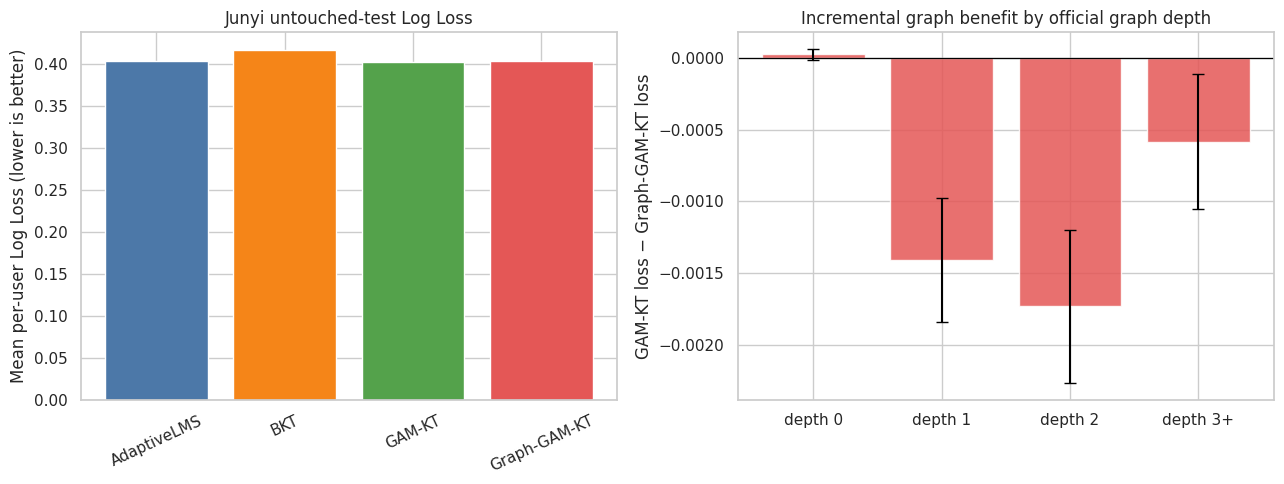

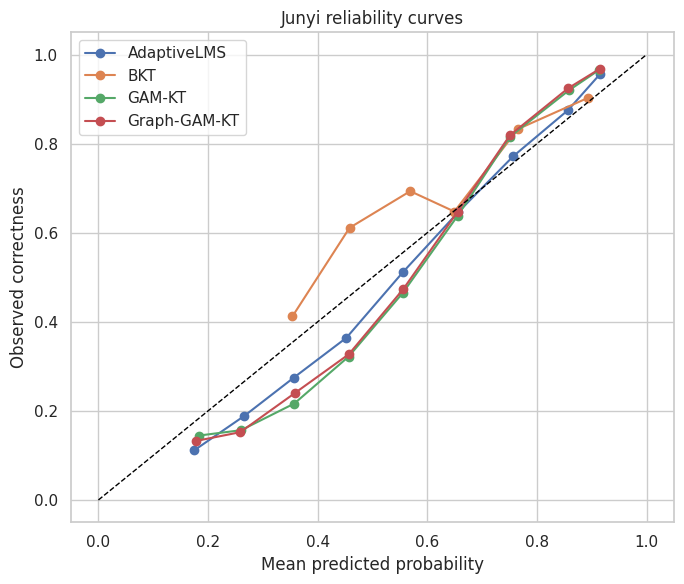

,depth_bin,users,events,mean_benefit,sem,ci_low,ci_high
0,depth 0,746,18220,0.000025,0.000019,-0.000012,0.000062
1,depth 1,541,8725,-0.001408,0.000221,-0.001841,-0.000975
2,depth 2,433,6306,-0.001734,0.000273,-0.002269,-0.001199
3,depth 3+,975,90331,-0.000584,0.000239,-0.001053,-0.000116


In [13]:
aligned = evaluation_predictions.pivot_table(
    index=["user_id_hash", "event_index", "exercise", "graph_depth", "parent_count", "y_true"],
    columns="model", values="p_pred", aggfunc="first",
).reset_index()

for model in ["GAM-KT", "Graph-GAM-KT"]:
    probability = np.clip(aligned[model].to_numpy(), 1e-6, 1 - 1e-6)
    y = aligned["y_true"].to_numpy()
    aligned[f"loss_{model}"] = -(y * np.log(probability) + (1 - y) * np.log(1 - probability))

aligned["graph_logloss_benefit"] = aligned["loss_GAM-KT"] - aligned["loss_Graph-GAM-KT"]
aligned["depth_bin"] = pd.cut(
    aligned["graph_depth"], bins=[-1, 0, 1, 2, np.inf],
    labels=["depth 0", "depth 1", "depth 2", "depth 3+"],
)

benefit_by_user_depth = aligned.groupby(["user_id_hash", "depth_bin"], observed=True).agg(
    graph_logloss_benefit=("graph_logloss_benefit", "mean"),
    events=("event_index", "size"),
).reset_index()

depth_summary = benefit_by_user_depth.groupby("depth_bin", observed=True).agg(
    users=("user_id_hash", "nunique"),
    events=("events", "sum"),
    mean_benefit=("graph_logloss_benefit", "mean"),
    sem=("graph_logloss_benefit", "sem"),
).reset_index()
depth_summary["ci_low"] = depth_summary["mean_benefit"] - 1.96 * depth_summary["sem"]
depth_summary["ci_high"] = depth_summary["mean_benefit"] + 1.96 * depth_summary["sem"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

plot_order = ["AdaptiveLMS", "BKT", "GAM-KT", "Graph-GAM-KT"]
plot_summary = summary_metrics.set_index("model").reindex(plot_order).reset_index()
axes[0].bar(plot_summary["model"], plot_summary["log_loss"], color=["#4c78a8", "#f58518", "#54a24b", "#e45756"])
axes[0].set_title("Junyi untouched-test Log Loss")
axes[0].set_ylabel("Mean per-user Log Loss (lower is better)")
axes[0].tick_params(axis="x", rotation=25)

x = np.arange(len(depth_summary))
y = depth_summary["mean_benefit"].to_numpy()
yerr = np.vstack([
    y - depth_summary["ci_low"].to_numpy(),
    depth_summary["ci_high"].to_numpy() - y,
])
axes[1].bar(x, y, color="#e45756", alpha=0.85)
axes[1].errorbar(x, y, yerr=yerr, fmt="none", ecolor="black", capsize=4)
axes[1].axhline(0, color="black", linewidth=0.9)
axes[1].set_xticks(x, depth_summary["depth_bin"].astype(str))
axes[1].set_title("Incremental graph benefit by official graph depth")
axes[1].set_ylabel("GAM-KT loss − Graph-GAM-KT loss")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "junyi_primary_results.png", dpi=220, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 6))
edges = np.linspace(0, 1, 11)
for model in plot_order:
    group = evaluation_predictions[evaluation_predictions["model"] == model]
    ids = np.clip(np.digitize(group["p_pred"], edges[1:-1]), 0, 9)
    points = []
    for bin_id in range(10):
        mask = ids == bin_id
        if mask.any():
            points.append((group.loc[mask, "p_pred"].mean(), group.loc[mask, "y_true"].mean(), mask.sum()))
    if points:
        ax.plot([p[0] for p in points], [p[1] for p in points], marker="o", label=model)
ax.plot([0, 1], [0, 1], "--", color="black", linewidth=1)
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed correctness")
ax.set_title("Junyi reliability curves")
ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "junyi_reliability_curves.png", dpi=220, bbox_inches="tight")
plt.show()

display(depth_summary.round(6))


## 9. Reproducibility manifest and export


In [14]:
def sha256_file(path, block_size=8 * 1024 * 1024):
    digest = hashlib.sha256()
    with open(path, "rb") as stream:
        while True:
            block = stream.read(block_size)
            if not block:
                break
            digest.update(block)
    return digest.hexdigest()


difficulty_export = difficulty_stats.reset_index()[["exercise", "count", "p_smoothed"]].copy()
difficulty_export["elo_difficulty"] = difficulty_export["exercise"].map(difficulty_map)

metrics_by_user.to_csv(OUTPUT_DIR / "junyi_metrics_by_user.csv", index=False)
summary_metrics.to_csv(OUTPUT_DIR / "junyi_metrics_summary.csv", index=False)
paired_tests.to_csv(OUTPUT_DIR / "junyi_paired_tests_holm.csv", index=False)
model_selection.to_csv(OUTPUT_DIR / "junyi_development_model_selection.csv", index=False)
difficulty_export.to_csv(OUTPUT_DIR / "junyi_train_only_difficulty.csv", index=False)
depth_summary.to_csv(OUTPUT_DIR / "junyi_graph_depth_benefit.csv", index=False)
test_predictions.to_csv(
    OUTPUT_DIR / "junyi_test_predictions.csv.gz", index=False, compression="gzip"
)

manifest = {
    "experiment": "junyi_external_validation_graph_gam_kt",
    "created_utc": pd.Timestamp.now(tz="UTC").isoformat(),
    "smoke_test": SMOKE_TEST,
    "dataset": "Junyi Academy Jan 2015 release",
    "dataset_documentation": "https://edudata.readthedocs.io/en/doc/build/blitz/junyi/junyi.html",
    "noncommercial_terms_acknowledged_by_runner": bool(ACCEPT_JUNYI_NONCOMMERCIAL_TERMS),
    "files": {
        "problem_log_name": PROBLEM_LOG.name,
        "problem_log_sha256": sha256_file(PROBLEM_LOG),
        "exercise_table_name": EXERCISE_TABLE.name,
        "exercise_table_sha256": sha256_file(EXERCISE_TABLE),
    },
    "split": {
        "unit": "user",
        "hash": "sha256 with fixed salt",
        "ratios": {"train": 0.70, "dev": 0.15, "test": 0.15},
        "selected_users": {key: len(value) for key, value in selected_by_split.items()},
        "events": {key: int(value) for key, value in events.groupby("split").size().items()},
        "minimum_events_per_user": MIN_EVENTS_PER_USER,
        "maximum_events_per_user": MAX_EVENTS_PER_USER,
        "evaluation_warmup_events": EVAL_WARMUP_EVENTS,
    },
    "graph": {
        "source": EXERCISE_TABLE.name,
        "field": PREREQ_COL,
        "nodes": graph.number_of_nodes(),
        "edges": graph.number_of_edges(),
        "is_dag": bool(is_dag),
    },
    "models": list(POLICY_FACTORIES),
    "selected_bkt_parameters": BKT_PARAMS,
    "selected_shared_decay": best_decay,
    "selected_graph_weight": best_graph_weight,
    "feature_source": "stable-hashed exercise/problem-type/topic/area/depth metadata",
    "feature_dimension": FEATURE_DIM,
    "difficulty_source": "train users only with empirical-Bayes smoothing",
    "test_exercise_oov_rate": test_oov_rate,
    "predict_before_update": True,
    "target_used_as_feature": False,
    "test_used_for_tuning": False,
    "metrics": ["log_loss", "brier", "ece", "auc", "accuracy"],
    "ece_bins": 5,
    "inference": {
        "unit": "user",
        "paired_test": "two-sided Wilcoxon signed-rank",
        "bootstrap_samples": BOOTSTRAP_SAMPLES,
        "effect_size": "rank-biserial correlation on benefit direction",
        "multiple_testing": "Holm across all primary comparisons",
    },
    "runtime": {
        "test_elapsed_seconds": elapsed_seconds,
        "predictions_per_second": len(test_predictions) / max(elapsed_seconds, 1e-9),
        "device": "CPU; models are sequential online updates",
    },
    "claim_boundary": (
        "Real logged data supports next-response estimation and calibration claims only; "
        "it does not identify causal learning or closed-loop policy effects."
    ),
}

(OUTPUT_DIR / "junyi_experiment_manifest.json").write_text(
    json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8"
)

paper_result_columns = [
    "baseline", "metric", "raw_delta", "bootstrap_ci_low",
    "bootstrap_ci_high", "p_holm", "conclusion",
]
paper_result_table = paired_tests[paper_result_columns].round(6)
markdown_header = "| " + " | ".join(paper_result_columns) + " |"
markdown_rule = "|" + "|".join(["---"] * len(paper_result_columns)) + "|"
markdown_rows = [
    "| " + " | ".join(map(str, row)) + " |"
    for row in paper_result_table.itertuples(index=False, name=None)
]
paper_result_markdown = "\n".join([markdown_header, markdown_rule, *markdown_rows])

summary_text = f"""# Junyi external-validation frozen summary

- Users: train={len(selected_by_split['train'])}, dev={len(selected_by_split['dev'])}, test={len(selected_by_split['test'])}.
- Test events: {len(test_events):,}; predictions: {len(test_predictions):,}.
- Official prerequisite graph: {graph.number_of_nodes()} nodes, {graph.number_of_edges()} edges; DAG={is_dag}.
- BKT parameters selected on development users: `{json.dumps(BKT_PARAMS)}`.
- Shared GAM decay: {best_decay}; graph weight: {best_graph_weight}.
- Predict-before-update: true; target used as feature: false; test used for tuning: false.

## Primary corrected conclusions

{paper_result_markdown}

## Claim boundary

Junyi validates estimation/calibration on real logged interactions. It does not establish causal learning gain or closed-loop policy benefit.
"""
(OUTPUT_DIR / "junyi_frozen_result_summary.md").write_text(summary_text, encoding="utf-8")

archive_path = Path(shutil.make_archive(str(OUTPUT_DIR), "zip", root_dir=OUTPUT_DIR))

if DRIVE_RESULT_DIR is not None:
    DRIVE_RESULT_DIR.mkdir(parents=True, exist_ok=True)
    for path in OUTPUT_DIR.iterdir():
        if path.is_file():
            shutil.copy2(path, DRIVE_RESULT_DIR / path.name)
    shutil.copy2(archive_path, DRIVE_RESULT_DIR / archive_path.name)

print(summary_text)
print({"output_archive": str(archive_path), "drive_result_dir": str(DRIVE_RESULT_DIR) if DRIVE_RESULT_DIR else None})


# Junyi external-validation frozen summary

- Users: train=4000, dev=1000, test=1000.
- Test events: 128,582; predictions: 514,328.
- Official prerequisite graph: 835 nodes, 979 edges; DAG=False.
- BKT parameters selected on development users: `{"p_init": 0.5, "p_learn": 0.1, "p_guess": 0.25, "p_slip": 0.1}`.
- Shared GAM decay: 0.0; graph weight: 0.15.
- Predict-before-update: true; target used as feature: false; test used for tuning: false.

## Primary corrected conclusions

| baseline | metric | raw_delta | bootstrap_ci_low | bootstrap_ci_high | p_holm | conclusion |
|---|---|---|---|---|---|---|
| AdaptiveLMS | auc | 0.039393 | 0.032869 | 0.045801 | 0.0 | Graph better |
| AdaptiveLMS | log_loss | -0.00097 | -0.003704 | 0.001886 | 0.004503 | Graph better |
| AdaptiveLMS | brier | -0.002204 | -0.003226 | -0.00125 | 0.371977 | No corrected difference |
| AdaptiveLMS | ece | 0.014858 | 0.012371 | 0.017196 | 0.0 | Graph worse |
| BKT | auc | 0.048454 | 0.043263 | 0.053543 | 0.0 | Graph 

# 10. Cycle-corrected ablation and independent confirmation

Các mục 1–9 ở trên được giữ nguyên như một **exploratory frozen run**. Sau khi test cũ đã được mở, ta không được sửa graph rồi tiếp tục gọi lại chính tập test đó là “untouched”. Phần này vì vậy:

1. loại các cạnh nội bộ trong strongly connected components để thu được DAG mà không nhìn target;
2. tách graph signal và graph-dependent adaptation thành ablation riêng;
3. thêm `graph_weight=0` và các trọng số nhỏ vào development grid;
4. chọn user hoàn toàn chưa xuất hiện trong train/dev/test cũ;
5. dùng confirmation-development để khóa variant/weight, rồi chỉ mở confirmation-test một lần;
6. chỉ kết luận có hướng khi **cả Holm-adjusted test và bootstrap CI theo benefit direction** cùng đồng ý.

Difficulty vẫn được ước lượng từ train users ban đầu. Đây là tham số global duy nhất học từ response; confirmation users không đóng góp vào difficulty hoặc tuning trước khi được gán vai trò.


In [15]:
RUN_CONFIRMATION_TEST = True
CONFIRM_DEV_USER_CAP = 1_000
CONFIRM_TEST_USER_CAP = 1_000
CONFIRM_TUNE_USER_CAP = 300
CONFIRM_GRAPH_WEIGHT_GRID = [0.0, 0.025, 0.05, 0.10, 0.15, 0.35]

if QUICK_MODE:
    CONFIRM_DEV_USER_CAP, CONFIRM_TEST_USER_CAP, CONFIRM_TUNE_USER_CAP = 250, 250, 100
if SMOKE_TEST:
    CONFIRM_DEV_USER_CAP, CONFIRM_TEST_USER_CAP, CONFIRM_TUNE_USER_CAP = 8, 8, 5

CONFIRM_OUTPUT_DIR = (
    Path("/content/junyi_cycle_corrected_confirmation_outputs")
    if IN_COLAB else Path("./junyi_cycle_corrected_confirmation_outputs")
)
CONFIRM_DRIVE_RESULT_DIR = (
    Path("/content/drive/MyDrive/Graduation-Thesis-Research/rivf-2026/results")
    if IN_COLAB else None
)
CONFIRM_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Remove every edge internal to a non-trivial SCC. Cross-component edges are retained.
sccs = list(nx.strongly_connected_components(graph))
component_by_node = {
    node: component_index
    for component_index, component in enumerate(sccs)
    for node in component
}
cyclic_sccs = [component for component in sccs if len(component) > 1]
removed_cycle_edges = [
    (source, target)
    for source, target in graph.edges()
    if component_by_node[source] == component_by_node[target]
]
graph_dag = graph.copy()
graph_dag.remove_edges_from(removed_cycle_edges)
assert nx.is_directed_acyclic_graph(graph_dag)

dag_depth = {}
for node in nx.topological_sort(graph_dag):
    parents = list(graph_dag.predecessors(node))
    dag_depth[node] = 0 if not parents else 1 + max(dag_depth[parent] for parent in parents)

unused_eligible = sorted(
    set(eligible) - set(selected_users),
    key=lambda user_id: stable_hash_int(user_id, "confirmation-pool-v1"),
)
required_confirmation_users = CONFIRM_DEV_USER_CAP + CONFIRM_TEST_USER_CAP
if len(unused_eligible) < required_confirmation_users:
    raise RuntimeError(
        f"Need {required_confirmation_users} unused eligible users but found {len(unused_eligible)}. "
        "Reduce confirmation caps only for a smoke/debug run; do not silently reuse old users."
    )

confirm_dev_users = set(unused_eligible[:CONFIRM_DEV_USER_CAP])
confirm_test_users = set(
    unused_eligible[CONFIRM_DEV_USER_CAP:required_confirmation_users]
)
confirm_selected_users = confirm_dev_users | confirm_test_users
assert confirm_selected_users.isdisjoint(selected_users)
assert confirm_dev_users.isdisjoint(confirm_test_users)

confirm_split_lookup = {
    **{user_id: "confirm_dev" for user_id in confirm_dev_users},
    **{user_id: "confirm_test" for user_id in confirm_test_users},
}

confirm_chunks = []
for chunk in pd.read_csv(PROBLEM_LOG, usecols=usecols, chunksize=CHUNK_SIZE, low_memory=False):
    mask = chunk[USER_COL].astype(str).isin(confirm_selected_users)
    if mask.any():
        confirm_chunks.append(chunk.loc[mask].copy())

confirm_events = pd.concat(confirm_chunks, ignore_index=True)
confirm_events = confirm_events.rename(columns={
    USER_COL: "user_id", EXERCISE_COL: "exercise",
    TIME_COL: "time_raw", CORRECT_COL: "correct_raw",
})
if PROBLEM_TYPE_COL:
    confirm_events = confirm_events.rename(columns={PROBLEM_TYPE_COL: "problem_type"})
else:
    confirm_events["problem_type"] = "unknown_template"

confirm_events["user_id"] = confirm_events["user_id"].astype(str)
confirm_events["exercise"] = confirm_events["exercise"].astype(str)
confirm_events["problem_type"] = (
    confirm_events["problem_type"].fillna("unknown_template").astype(str)
)
confirm_events["y"] = parse_correct(confirm_events["correct_raw"])
confirm_events["timestamp"] = parse_timestamp(confirm_events["time_raw"])
confirm_events = confirm_events[
    confirm_events["y"].isin([0, 1])
    & confirm_events["timestamp"].notna()
    & confirm_events["exercise"].ne("")
].copy()
confirm_events["y"] = confirm_events["y"].astype(int)
confirm_events["split"] = confirm_events["user_id"].map(confirm_split_lookup)
confirm_events = confirm_events.drop_duplicates(
    ["user_id", "timestamp", "exercise", "problem_type", "y"]
)
confirm_events = confirm_events.sort_values(
    ["user_id", "timestamp", "exercise", "problem_type"]
).reset_index(drop=True)
confirm_events["event_index"] = confirm_events.groupby("user_id").cumcount()
confirm_events = confirm_events[
    confirm_events["event_index"] < MAX_EVENTS_PER_USER
].copy()
confirm_events["question_id"] = (
    confirm_events["exercise"] + "||" + confirm_events["problem_type"]
)
confirm_events["difficulty"] = (
    confirm_events["exercise"].map(difficulty_map).fillna(GLOBAL_DIFFICULTY)
)
confirm_events["graph_depth"] = (
    confirm_events["exercise"].map(dag_depth).fillna(0).astype(int)
)
confirm_events["parent_count"] = (
    confirm_events["exercise"].map(dict(graph_dag.in_degree())).fillna(0).astype(int)
)

assert confirm_events["split"].notna().all()
assert not confirm_events.duplicated(["user_id", "event_index"]).any()

confirmation_split_summary = confirm_events.groupby("split").agg(
    users=("user_id", "nunique"), events=("user_id", "size"),
    exercises=("exercise", "nunique"), correct_rate=("y", "mean"),
).reindex(["confirm_dev", "confirm_test"])

print({
    "raw_graph": {"nodes": graph.number_of_nodes(), "edges": graph.number_of_edges(), "dag": is_dag},
    "cycle_correction": {
        "cyclic_sccs": len(cyclic_sccs),
        "nodes_in_cyclic_sccs": sum(len(component) for component in cyclic_sccs),
        "removed_internal_edges": len(removed_cycle_edges),
        "corrected_edges": graph_dag.number_of_edges(),
        "corrected_is_dag": nx.is_directed_acyclic_graph(graph_dag),
    },
    "old_and_confirmation_user_overlap": len(set(selected_users) & confirm_selected_users),
})
display(confirmation_split_summary.round(4))


{'raw_graph': {'nodes': 835, 'edges': 979, 'dag': False}, 'cycle_correction': {'cyclic_sccs': 1, 'nodes_in_cyclic_sccs': 3, 'removed_internal_edges': 3, 'corrected_edges': 976, 'corrected_is_dag': True}, 'old_and_confirmation_user_overlap': 0}


,users,events,exercises,correct_rate
split,,,,
confirm_dev,1000,131530,546,0.8347
confirm_test,1000,127923,559,0.8349


## 11. Confirmation-development ablation and locked selection


In [16]:
confirm_dev_events = confirm_events[confirm_events["split"] == "confirm_dev"].copy()
confirm_dev_order = sorted(
    confirm_dev_events["user_id"].unique(),
    key=lambda user_id: stable_hash_int(user_id, "confirmation-dev-tune-v1"),
)
confirm_tune_users = set(confirm_dev_order[:CONFIRM_TUNE_USER_CAP])
confirm_dev_tune_events = confirm_dev_events[
    confirm_dev_events["user_id"].isin(confirm_tune_users)
].copy()

CONFIRM_VARIANTS = {
    "DAG-Signal": {"signal": True, "adaptation": False},
    "DAG-Adaptation": {"signal": False, "adaptation": True},
    "DAG-Full": {"signal": True, "adaptation": True},
}


def confirmation_model(variant, graph_weight, graph_source=graph_dag, model_name=None):
    if variant == "GAM-KT":
        signal_enabled, adaptation_enabled = False, False
    else:
        spec = CONFIRM_VARIANTS[variant]
        signal_enabled = spec["signal"]
        adaptation_enabled = spec["adaptation"]
    return GAMKTModel(
        use_graph_context=signal_enabled or adaptation_enabled,
        time_decay_rate=best_decay,
        graph_weight=graph_weight,
        graph_source=graph_source,
        graph_signal_enabled=signal_enabled,
        graph_adaptation_enabled=adaptation_enabled,
        name=model_name or variant,
    )


confirm_selection_rows = [{
    "variant": "GAM-KT",
    "graph_weight": 0.0,
    "dev_log_loss": sequential_mean_log_loss(
        confirm_dev_tune_events,
        lambda: confirmation_model("GAM-KT", 0.0),
    ),
    "eligible_for_lock": False,
    "role": "non-graph reference",
}]

for variant, spec in CONFIRM_VARIANTS.items():
    weight_grid = (
        CONFIRM_GRAPH_WEIGHT_GRID if spec["signal"] else [0.0]
    )
    for graph_weight in weight_grid:
        score = sequential_mean_log_loss(
            confirm_dev_tune_events,
            lambda v=variant, w=graph_weight: confirmation_model(v, w),
        )
        confirm_selection_rows.append({
            "variant": variant,
            "graph_weight": graph_weight,
            "dev_log_loss": score,
            "eligible_for_lock": True,
            "role": "cycle-corrected candidate",
        })

confirmation_model_selection = pd.DataFrame(confirm_selection_rows)
locked_row = confirmation_model_selection[
    confirmation_model_selection["eligible_for_lock"]
].sort_values(["dev_log_loss", "variant", "graph_weight"]).iloc[0]
LOCKED_GRAPH_VARIANT = str(locked_row["variant"])
LOCKED_GRAPH_WEIGHT = float(locked_row["graph_weight"])
LOCKED_DECAY = float(best_decay)

# Diagnostic only: same locked ablation and weight on the raw cyclic graph.
raw_graph_score = sequential_mean_log_loss(
    confirm_dev_tune_events,
    lambda: confirmation_model(
        LOCKED_GRAPH_VARIANT,
        LOCKED_GRAPH_WEIGHT,
        graph_source=graph,
        model_name="RawGraph-Diagnostic",
    ),
)
confirmation_model_selection = pd.concat([
    confirmation_model_selection,
    pd.DataFrame([{
        "variant": "RawGraph-Diagnostic",
        "graph_weight": LOCKED_GRAPH_WEIGHT,
        "dev_log_loss": raw_graph_score,
        "eligible_for_lock": False,
        "role": "cycle diagnostic only",
    }]),
], ignore_index=True)

gam_dev_loss = float(
    confirmation_model_selection.loc[
        confirmation_model_selection["variant"] == "GAM-KT", "dev_log_loss"
    ].iloc[0]
)

print({
    "confirmation_dev_tune_users": len(confirm_tune_users),
    "confirmation_test_rows_accessed_during_selection": 0,
    "locked_variant": LOCKED_GRAPH_VARIANT,
    "locked_graph_weight": LOCKED_GRAPH_WEIGHT,
    "locked_decay": LOCKED_DECAY,
    "locked_dev_log_loss": float(locked_row["dev_log_loss"]),
    "gam_dev_log_loss": gam_dev_loss,
    "graph_candidate_beats_gam_on_dev": bool(float(locked_row["dev_log_loss"]) < gam_dev_loss),
})
display(confirmation_model_selection.sort_values("dev_log_loss").round(6))


{'confirmation_dev_tune_users': 300, 'confirmation_test_rows_accessed_during_selection': 0, 'locked_variant': 'DAG-Signal', 'locked_graph_weight': 0.0, 'locked_decay': 0.0, 'locked_dev_log_loss': 0.38600858998593474, 'gam_dev_log_loss': 0.38600858998593474, 'graph_candidate_beats_gam_on_dev': False}


,variant,graph_weight,dev_log_loss,eligible_for_lock,role
0,GAM-KT,0.000,0.386009,False,non-graph reference
1,DAG-Signal,0.000,0.386009,True,cycle-corrected candidate
14,RawGraph-Diagnostic,0.000,0.386009,False,cycle diagnostic only
2,DAG-Signal,0.025,0.386072,True,cycle-corrected candidate
3,DAG-Signal,0.050,0.386136,True,cycle-corrected candidate
4,DAG-Signal,0.100,0.386268,True,cycle-corrected candidate
5,DAG-Signal,0.150,0.386403,True,cycle-corrected candidate
7,DAG-Adaptation,0.000,0.386697,True,cycle-corrected candidate
8,DAG-Full,0.000,0.386697,True,cycle-corrected candidate
9,DAG-Full,0.025,0.386760,True,cycle-corrected candidate


## 12. One-shot independent confirmation test

Sau khi cell selection phía trên in ra cấu hình khóa, không sửa variant/weight theo kết quả bên dưới. Nếu thay đổi thiết kế sau khi chạy cell này, confirmation-test v1 cũng phải được đánh dấu là đã mở và cần một holdout mới.


In [17]:
if not RUN_CONFIRMATION_TEST:
    raise RuntimeError(
        "Set RUN_CONFIRMATION_TEST=True only after the corrected graph and ablation grid are frozen."
    )

LOCKED_MODEL_NAME = f"Locked-{LOCKED_GRAPH_VARIANT}"
CONFIRM_POLICY_FACTORIES = {
    "AdaptiveLMS": AdaptiveLMSModel,
    "BKT": lambda: BKTModel(**BKT_PARAMS),
    "GAM-KT": lambda: confirmation_model("GAM-KT", 0.0, model_name="GAM-KT"),
    LOCKED_MODEL_NAME: lambda: confirmation_model(
        LOCKED_GRAPH_VARIANT,
        LOCKED_GRAPH_WEIGHT,
        model_name=LOCKED_MODEL_NAME,
    ),
}

confirm_test_events = confirm_events[confirm_events["split"] == "confirm_test"].copy()
confirmation_prediction_rows = []
confirmation_start = time.perf_counter()

for user_id, group in confirm_test_events.groupby("user_id", sort=False):
    ordered = group.sort_values("event_index")
    user_hash = hashlib.sha256(
        f"confirmation-v1|{user_id}".encode("utf-8")
    ).hexdigest()[:16]
    for model_name, factory in CONFIRM_POLICY_FACTORIES.items():
        model = factory()
        for event in ordered.itertuples(index=False):
            p_pred = float(np.clip(model.predict(
                event.exercise, event.problem_type, event.difficulty, event.timestamp
            ), 1e-6, 1 - 1e-6))
            confirmation_prediction_rows.append({
                "model": model_name,
                "user_id_hash": user_hash,
                "event_index": int(event.event_index),
                "timestamp": event.timestamp,
                "exercise": event.exercise,
                "question_id": event.question_id,
                "graph_depth": int(event.graph_depth),
                "parent_count": int(event.parent_count),
                "y_true": int(event.y),
                "p_pred": p_pred,
                "is_evaluation": bool(event.event_index >= EVAL_WARMUP_EVENTS),
            })
            model.update(
                event.exercise, event.problem_type, event.difficulty,
                event.timestamp, event.y, p_pred,
            )

confirmation_predictions = pd.DataFrame(confirmation_prediction_rows)
confirmation_elapsed = time.perf_counter() - confirmation_start
expected_confirmation_predictions = len(confirm_test_events) * len(CONFIRM_POLICY_FACTORIES)
assert len(confirmation_predictions) == expected_confirmation_predictions
assert not confirmation_predictions.duplicated(
    ["model", "user_id_hash", "event_index"]
).any()
assert np.isfinite(confirmation_predictions["p_pred"]).all()
assert confirmation_predictions["p_pred"].between(0, 1).all()

print({
    "confirmation_test_users": confirm_test_events["user_id"].nunique(),
    "confirmation_test_events": len(confirm_test_events),
    "predictions": len(confirmation_predictions),
    "models": list(CONFIRM_POLICY_FACTORIES),
    "elapsed_seconds": round(confirmation_elapsed, 2),
    "predictions_per_second": round(
        len(confirmation_predictions) / max(confirmation_elapsed, 1e-9), 1
    ),
})


{'confirmation_test_users': 1000, 'confirmation_test_events': 127923, 'predictions': 511692, 'models': ['AdaptiveLMS', 'BKT', 'GAM-KT', 'Locked-DAG-Signal'], 'elapsed_seconds': 64.14, 'predictions_per_second': 7978.1}


## 13. Aligned inference, figures, and paper-ready export


,model,users,log_loss,brier,ece,auc,accuracy
0,AdaptiveLMS,1000,0.394373,0.121473,0.089281,0.680991,0.836778
1,BKT,1000,0.408671,0.126117,0.101649,0.668742,0.835354
2,GAM-KT,1000,0.393592,0.119530,0.102439,0.718140,0.841173
3,Locked-DAG-Signal,1000,0.393592,0.119530,0.102439,0.718140,0.841173


,protocol,proposed,baseline,metric,n_user_pairs,proposed_mean,baseline_mean,raw_delta,benefit_delta,benefit_ci_low,benefit_ci_high,rank_biserial_benefit,wilcoxon_stat,p_value,p_holm,reject_holm_05,conclusion
0,junyi_confirmation_v1,Locked-DAG-Signal,GAM-KT,auc,968,0.718140,0.718140,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,False,No robust corrected difference
1,junyi_confirmation_v1,Locked-DAG-Signal,GAM-KT,log_loss,1000,0.393592,0.393592,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,False,No robust corrected difference
2,junyi_confirmation_v1,Locked-DAG-Signal,GAM-KT,brier,1000,0.119530,0.119530,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,False,No robust corrected difference
3,junyi_confirmation_v1,Locked-DAG-Signal,GAM-KT,ece,1000,0.102439,0.102439,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,False,No robust corrected difference


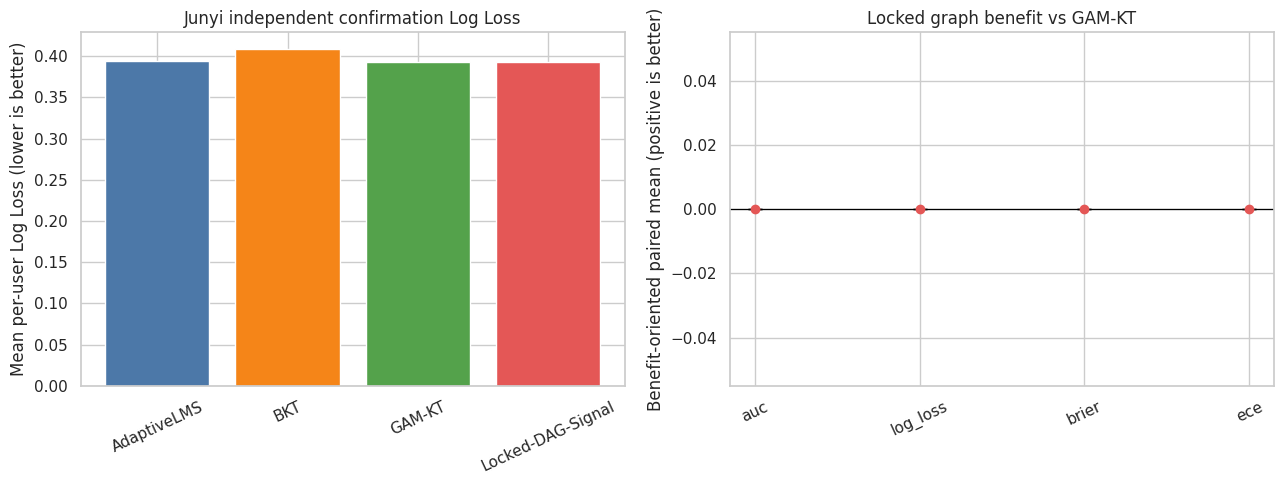

# Junyi cycle-corrected confirmation — frozen summary

- Old test status: exploratory and already opened.
- Independent confirmation users: dev=1000, test=1000; overlap with old users=0.
- Cycle correction: 1 cyclic SCCs; removed 3 internal edges; corrected DAG=true.
- Locked development choice: `Locked-DAG-Signal`, graph_weight=0.0, decay=0.0.
- Confirmation test events: 127,923; predictions: 511,692.
- Prediction-before-update=true; confirmation-test used for tuning=false.

## Primary locked comparison against GAM-KT

| metric | raw_delta | benefit_delta | benefit_ci_low | benefit_ci_high | p_holm | conclusion |
|---|---|---|---|---|---|---|
| auc | 0.0 | 0.0 | 0.0 | 0.0 | 1.0 | No robust corrected difference |
| log_loss | 0.0 | 0.0 | 0.0 | 0.0 | 1.0 | No robust corrected difference |
| brier | 0.0 | 0.0 | 0.0 | 0.0 | 1.0 | No robust corrected difference |
| ece | 0.0 | 0.0 | 0.0 | 0.0 | 1.0 | No robust corrected difference |

## Claim boundary

Junyi supports next-response estimati

In [18]:
confirmation_eval = confirmation_predictions[
    confirmation_predictions["is_evaluation"]
].copy()
confirmation_metric_rows = []
for (model, user_id_hash), group in confirmation_eval.groupby(
    ["model", "user_id_hash"]
):
    y = group["y_true"].to_numpy()
    p = group["p_pred"].to_numpy()
    if len(y) < 10:
        continue
    confirmation_metric_rows.append({
        "model": model,
        "user_id_hash": user_id_hash,
        "n_events": len(y),
        "accuracy": accuracy_score(y, p >= 0.5),
        "auc": roc_auc_score(y, p) if len(np.unique(y)) == 2 else np.nan,
        "log_loss": log_loss(y, p, labels=[0, 1]),
        "brier": brier_score_loss(y, p),
        "ece": expected_calibration_error(y, p),
    })

confirmation_metrics_by_user = pd.DataFrame(confirmation_metric_rows)
confirmation_summary_metrics = confirmation_metrics_by_user.groupby("model").agg(
    users=("user_id_hash", "nunique"),
    log_loss=("log_loss", "mean"),
    brier=("brier", "mean"),
    ece=("ece", "mean"),
    auc=("auc", "mean"),
    accuracy=("accuracy", "mean"),
).reset_index()

primary_directions = {"auc": 1, "log_loss": -1, "brier": -1, "ece": -1}
confirmation_test_rows = []
pivot_cache = {}
for metric_index, (metric, direction) in enumerate(primary_directions.items()):
    pivot = confirmation_metrics_by_user.pivot(
        index="user_id_hash", columns="model", values=metric
    )[[LOCKED_MODEL_NAME, "GAM-KT"]].dropna()
    pivot_cache[metric] = pivot
    raw_delta = (pivot[LOCKED_MODEL_NAME] - pivot["GAM-KT"]).to_numpy()
    benefit = direction * raw_delta
    if np.allclose(benefit, 0):
        statistic, p_value = 0.0, 1.0
    else:
        statistic, p_value = wilcoxon(
            benefit, zero_method="wilcox", alternative="two-sided"
        )
    benefit_ci_low, benefit_ci_high = bootstrap_mean_ci(
        benefit,
        GLOBAL_SEED + 10_000 + metric_index,
    )
    confirmation_test_rows.append({
        "protocol": "junyi_confirmation_v1",
        "proposed": LOCKED_MODEL_NAME,
        "baseline": "GAM-KT",
        "metric": metric,
        "n_user_pairs": len(benefit),
        "proposed_mean": float(pivot[LOCKED_MODEL_NAME].mean()),
        "baseline_mean": float(pivot["GAM-KT"].mean()),
        "raw_delta": float(raw_delta.mean()),
        "benefit_delta": float(benefit.mean()),
        "benefit_ci_low": benefit_ci_low,
        "benefit_ci_high": benefit_ci_high,
        "rank_biserial_benefit": rank_biserial(benefit),
        "wilcoxon_stat": statistic,
        "p_value": p_value,
    })

confirmation_paired_tests = pd.DataFrame(confirmation_test_rows)
confirmation_paired_tests["p_holm"] = holm_adjust(
    confirmation_paired_tests["p_value"].fillna(1.0)
)
confirmation_paired_tests["reject_holm_05"] = (
    confirmation_paired_tests["p_holm"] < 0.05
)


def robust_confirmation_conclusion(row):
    if row["reject_holm_05"] and row["benefit_ci_low"] > 0:
        return "Locked graph better"
    if row["reject_holm_05"] and row["benefit_ci_high"] < 0:
        return "Locked graph worse"
    return "No robust corrected difference"


confirmation_paired_tests["conclusion"] = confirmation_paired_tests.apply(
    robust_confirmation_conclusion, axis=1
)

display(confirmation_summary_metrics.round(6))
display(confirmation_paired_tests.round(6))

plot_order = ["AdaptiveLMS", "BKT", "GAM-KT", LOCKED_MODEL_NAME]
plot_summary = confirmation_summary_metrics.set_index("model").reindex(plot_order).reset_index()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].bar(
    plot_summary["model"], plot_summary["log_loss"],
    color=["#4c78a8", "#f58518", "#54a24b", "#e45756"],
)
axes[0].set_title("Junyi independent confirmation Log Loss")
axes[0].set_ylabel("Mean per-user Log Loss (lower is better)")
axes[0].tick_params(axis="x", rotation=25)

x = np.arange(len(confirmation_paired_tests))
benefit_mean = confirmation_paired_tests["benefit_delta"].to_numpy()
benefit_yerr = np.vstack([
    benefit_mean - confirmation_paired_tests["benefit_ci_low"].to_numpy(),
    confirmation_paired_tests["benefit_ci_high"].to_numpy() - benefit_mean,
])
axes[1].errorbar(
    x, benefit_mean, yerr=benefit_yerr,
    fmt="o", color="#e45756", ecolor="black", capsize=5,
)
axes[1].axhline(0, color="black", linewidth=0.9)
axes[1].set_xticks(x, confirmation_paired_tests["metric"], rotation=25)
axes[1].set_title("Locked graph benefit vs GAM-KT")
axes[1].set_ylabel("Benefit-oriented paired mean (positive is better)")
plt.tight_layout()
confirmation_figure_path = CONFIRM_OUTPUT_DIR / "junyi_confirmation_primary_results.png"
plt.savefig(confirmation_figure_path, dpi=220, bbox_inches="tight")
plt.show()

confirmation_model_selection.to_csv(
    CONFIRM_OUTPUT_DIR / "junyi_confirmation_model_selection.csv", index=False
)
confirmation_metrics_by_user.to_csv(
    CONFIRM_OUTPUT_DIR / "junyi_confirmation_metrics_by_user.csv", index=False
)
confirmation_summary_metrics.to_csv(
    CONFIRM_OUTPUT_DIR / "junyi_confirmation_metrics_summary.csv", index=False
)
confirmation_paired_tests.to_csv(
    CONFIRM_OUTPUT_DIR / "junyi_confirmation_paired_tests_holm.csv", index=False
)
confirmation_predictions.to_csv(
    CONFIRM_OUTPUT_DIR / "junyi_confirmation_predictions.csv.gz",
    index=False,
    compression="gzip",
)

confirmation_manifest = {
    "experiment": "junyi_cycle_corrected_independent_confirmation_v1",
    "created_utc": pd.Timestamp.now(tz="UTC").isoformat(),
    "dataset": "Junyi Academy Jan 2015 release",
    "old_run_status": "exploratory; test opened before cycle correction",
    "confirmation_status": "one-shot independent user holdout",
    "user_overlap_with_old_train_dev_test": 0,
    "confirmation_users": {
        "development": len(confirm_dev_users),
        "development_tuning_subset": len(confirm_tune_users),
        "test": len(confirm_test_users),
    },
    "selection_salts": {
        "pool": "confirmation-pool-v1",
        "dev_tune": "confirmation-dev-tune-v1",
    },
    "graph_correction": {
        "method": "remove all edges internal to strongly connected components",
        "target_used": False,
        "raw_nodes": graph.number_of_nodes(),
        "raw_edges": graph.number_of_edges(),
        "raw_is_dag": bool(is_dag),
        "cyclic_sccs": len(cyclic_sccs),
        "nodes_in_cyclic_sccs": sum(len(component) for component in cyclic_sccs),
        "removed_internal_edges": len(removed_cycle_edges),
        "corrected_edges": graph_dag.number_of_edges(),
        "corrected_is_dag": True,
    },
    "ablation_grid": {
        "variants": CONFIRM_VARIANTS,
        "graph_weights": CONFIRM_GRAPH_WEIGHT_GRID,
        "selection_metric": "mean sequential log loss on confirmation-development subset",
    },
    "locked_model": {
        "name": LOCKED_MODEL_NAME,
        "variant": LOCKED_GRAPH_VARIANT,
        "graph_weight": LOCKED_GRAPH_WEIGHT,
        "time_decay_rate": LOCKED_DECAY,
    },
    "difficulty_source": "original train users only",
    "predict_before_update": True,
    "target_used_as_feature": False,
    "confirmation_test_used_for_tuning": False,
    "primary_metrics": list(primary_directions),
    "inference": {
        "unit": "user",
        "paired_test": "two-sided Wilcoxon signed-rank",
        "bootstrap_quantity": "mean benefit-oriented paired delta",
        "bootstrap_samples": BOOTSTRAP_SAMPLES,
        "multiple_testing": "Holm across four locked-model-vs-GAM primary metrics",
        "directional_claim_rule": "Holm p<0.05 and bootstrap CI entirely on same side of zero",
    },
    "runtime": {
        "elapsed_seconds": confirmation_elapsed,
        "predictions_per_second": len(confirmation_predictions) / max(confirmation_elapsed, 1e-9),
        "device": "CPU; sequential online updates",
    },
    "claim_boundary": (
        "Logged Junyi data supports next-response estimation and calibration claims only; "
        "it does not identify causal learning or closed-loop policy effects."
    ),
}
(CONFIRM_OUTPUT_DIR / "junyi_confirmation_manifest.json").write_text(
    json.dumps(confirmation_manifest, ensure_ascii=False, indent=2), encoding="utf-8"
)

table_columns = [
    "metric", "raw_delta", "benefit_delta", "benefit_ci_low",
    "benefit_ci_high", "p_holm", "conclusion",
]
table = confirmation_paired_tests[table_columns].round(6)
table_header = "| " + " | ".join(table_columns) + " |"
table_rule = "|" + "|".join(["---"] * len(table_columns)) + "|"
table_rows = [
    "| " + " | ".join(map(str, row)) + " |"
    for row in table.itertuples(index=False, name=None)
]
confirmation_table_markdown = "\n".join([table_header, table_rule, *table_rows])

confirmation_summary_text = f"""# Junyi cycle-corrected confirmation — frozen summary

- Old test status: exploratory and already opened.
- Independent confirmation users: dev={len(confirm_dev_users)}, test={len(confirm_test_users)}; overlap with old users=0.
- Cycle correction: {len(cyclic_sccs)} cyclic SCCs; removed {len(removed_cycle_edges)} internal edges; corrected DAG=true.
- Locked development choice: `{LOCKED_MODEL_NAME}`, graph_weight={LOCKED_GRAPH_WEIGHT}, decay={LOCKED_DECAY}.
- Confirmation test events: {len(confirm_test_events):,}; predictions: {len(confirmation_predictions):,}.
- Prediction-before-update=true; confirmation-test used for tuning=false.

## Primary locked comparison against GAM-KT

{confirmation_table_markdown}

## Claim boundary

Junyi supports next-response estimation/calibration claims on real logged interactions. It does not establish causal learning gain or closed-loop policy benefit.
"""
(CONFIRM_OUTPUT_DIR / "junyi_confirmation_frozen_summary.md").write_text(
    confirmation_summary_text, encoding="utf-8"
)

confirmation_archive_path = Path(shutil.make_archive(
    str(CONFIRM_OUTPUT_DIR), "zip", root_dir=CONFIRM_OUTPUT_DIR
))
if CONFIRM_DRIVE_RESULT_DIR is not None:
    CONFIRM_DRIVE_RESULT_DIR.mkdir(parents=True, exist_ok=True)
    for path in CONFIRM_OUTPUT_DIR.iterdir():
        if path.is_file():
            shutil.copy2(path, CONFIRM_DRIVE_RESULT_DIR / path.name)
    shutil.copy2(
        confirmation_archive_path,
        CONFIRM_DRIVE_RESULT_DIR / confirmation_archive_path.name,
    )

print(confirmation_summary_text)
print({
    "confirmation_archive": str(confirmation_archive_path),
    "drive_result_dir": (
        str(CONFIRM_DRIVE_RESULT_DIR) if CONFIRM_DRIVE_RESULT_DIR else None
    ),
})


## Paper interpretation checklist

Chỉ claim incremental graph value từ `junyi_confirmation_v1`, không dùng kết quả exploratory cũ làm kiểm định chính.

1. Variant và graph weight phải được khóa trên confirmation-development.
2. Confirmation-test users phải có overlap bằng 0 với toàn bộ users cũ.
3. Một metric chỉ có kết luận hướng khi `p_holm < 0.05` và benefit bootstrap CI nằm hoàn toàn cùng phía của 0.
4. Nếu locked graph không thắng GAM-KT trên Log Loss/Brier, viết đây là evidence giới hạn hoặc trade-off, không “cherry-pick” AUC/accuracy.
5. Junyi không hỗ trợ claim causal learning/retention; phần đó vẫn thuộc controlled simulator.
